# Laboratorium 3: Od tokenów do reprezentacji wektorowych

W tym laboratorium porównamy rzadkie i gęste reprezentacje wektorowe oraz sprawdzimy, jak zachowują się w zadaniach opartych na podobieństwie tekstów.

Porównujemy:

- TF-IDF,
- `sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2`,
- `intfloat/multilingual-e5-small`.

Główne pytanie laboratorium:

**Czy bliskość dwóch tekstów w przestrzeni wektorowej odpowiada podobieństwu, którego potrzebujemy w konkretnym zadaniu NLP?**


## Po tych zajęciach student potrafi

- wyjaśnić różnicę między rzadką i gęstą reprezentacją wektorową;
- obliczyć i zinterpretować podobieństwo cosinusowe;
- wygenerować reprezentacje tekstu za pomocą modelu embeddingowego;
- zaimplementować wyszukiwanie najbliższych sąsiadów;
- ocenić jakość lokalnego sąsiedztwa;
- zbudować prosty benchmark wyszukiwania;
- zastosować PCA do analizy przestrzeni reprezentacji;
- rozpoznać przypadki, w których wysokie podobieństwo wektorowe nie odpowiada wymaganiom zadania;
- porównać jakość reprezentacji z jej kosztem obliczeniowym;
- uzasadnić wybór reprezentacji dla konkretnego zastosowania.


## Dane

Pracujemy na zbiorze PolEmo 2.0 wykorzystywanym w poprzednich laboratoriach.

Jeżeli istnieje plik:

```text
artifacts/polemo2_clean.parquet
```

należy użyć tej wersji danych. Jeśli pliku nie ma, proszę wrócić do Lab 1 i go przygotować.

W tym laboratorium nie używamy zbioru testowego do wyboru reprezentacji ani do strojenia eksperymentów.


## Ustawienia wstępne

Wymagane biblioteki:

```bash
pip install pandas numpy matplotlib scikit-learn pyarrow sentence-transformers
```

Kod startowy obejmuje wyłącznie importy, stałe i wczytanie danych. Implementacja eksperymentów należy do Państwa.


In [1]:
from pathlib import Path
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.neighbors import NearestNeighbors
from sklearn.decomposition import PCA

from sentence_transformers import SentenceTransformer

RANDOM_STATE = 42
SAMPLE_SIZE = 1000

ARTIFACTS = Path("artifacts")
ARTIFACTS.mkdir(exist_ok=True)

MODEL_A_NAME = "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"
MODEL_B_NAME = "intfloat/multilingual-e5-small"

pd.set_option("display.max_colwidth", 180)


c:\Users\lukas\Desktop\NaturaLanguageProcessing\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [4]:
DATA_PATH = ARTIFACTS / "polemo2_clean.parquet"
assert DATA_PATH.exists(), "Brak artifacts/polemo2_clean.parquet. Proszę wykonać Lab 1."

data = pd.read_parquet(DATA_PATH).dropna(subset=["text", "target"]).reset_index(drop=True)
assert set(data["target"]) == {"plus", "minus", "zero", "amb"}

train_df = data[data["split"] == "train"].reset_index(drop=True)  # tylko train, bez validation i test
print(train_df.shape)
display(train_df.head())

(5783, 6)


,text,target,split,text_raw,text_norm,duplicate_flag
0,"Super lekarz i człowiek przez duże C . Bardzo duże doświadczenie i trafne diagnozy . Wielka cierpliwość do ludzi starszych . Od lat opiekuje się moją Mamą staruszką , i twierdz...",plus,train,"Super lekarz i człowiek przez duże C . Bardzo duże doświadczenie i trafne diagnozy . Wielka cierpliwość do ludzi starszych . Od lat opiekuje się moją Mamą staruszką , i twierdz...","super lekarz i człowiek przez duże c . bardzo duże doświadczenie i trafne diagnozy . wielka cierpliwość do ludzi starszych . od lat opiekuje się moją mamą staruszką , i twierdz...",False
1,Bardzo olewcze podejscie do pacjenta . Przyprowadzajac dziecko z ostra wysypka na calym ciele trwajaca od 2 tygodni Pani doktor stwierdzila ze nie widzi wskazan wystawienia dzi...,minus,train,Bardzo olewcze podejscie do pacjenta . Przyprowadzajac dziecko z ostra wysypka na calym ciele trwajaca od 2 tygodni Pani doktor stwierdzila ze nie widzi wskazan wystawienia dzi...,bardzo olewcze podejscie do pacjenta . przyprowadzajac dziecko z ostra wysypka na calym ciele trwajaca od 2 tygodni pani doktor stwierdzila ze nie widzi wskazan wystawienia dzi...,False
2,"Lekarz zalecił mi kurację alternatywną do dotychczasowej , więc jeszcze nie daję najwyższej oceny ( zobaczymy na ile okaże się skuteczna ) . Do Pana doktora nie mam zastrzeżeń ...",amb,train,"Lekarz zalecił mi kurację alternatywną do dotychczasowej , więc jeszcze nie daję najwyższej oceny ( zobaczymy na ile okaże się skuteczna ) . Do Pana doktora nie mam zastrzeżeń ...","lekarz zalecił mi kurację alternatywną do dotychczasowej , więc jeszcze nie daję najwyższej oceny ( zobaczymy na ile okaże się skuteczna ) . do pana doktora nie mam zastrzeżeń ...",False
3,""" Konsumenci oczywiście kierują się ceną . Te leki są tańsze , ale dzisiaj nie możemy już powiedzieć , że znacznie tańsze . Jest to mniej krępujące , nie trzeba wychodzić z dom...",zero,train,""" Konsumenci oczywiście kierują się ceną . Te leki są tańsze , ale dzisiaj nie możemy już powiedzieć , że znacznie tańsze . Jest to mniej krępujące , nie trzeba wychodzić z dom...",""" konsumenci oczywiście kierują się ceną . te leki są tańsze , ale dzisiaj nie możemy już powiedzieć , że znacznie tańsze . jest to mniej krępujące , nie trzeba wychodzić z dom...",False
4,"Pani Doktor Iwona jest profesjonalistką w każdym calu : ) Idąc do stomatologa zawsze czuję przeraźliwy strach . Pani Doktor Iwona jest wyrozumiała i delikatna , bardzo miła , c...",plus,train,"Pani Doktor Iwona jest profesjonalistką w każdym calu : ) Idąc do stomatologa zawsze czuję przeraźliwy strach . Pani Doktor Iwona jest wyrozumiała i delikatna , bardzo miła , c...","pani doktor iwona jest profesjonalistką w każdym calu : ) idąc do stomatologa zawsze czuję przeraźliwy strach . pani doktor iwona jest wyrozumiała i delikatna , bardzo miła , c...",False


# Zadanie 1: TF-IDF i podobieństwo cosinusowe

Proszę rozpocząć od tekstów:

```text
A = "hotel czysty wygodny"
B = "hotel bardzo czysty"
C = "samochód szybki sportowy"
```

Proszę zaimplementować:

1. reprezentację TF-IDF;
2. tabelę wartości TF-IDF;
3. macierz podobieństwa cosinusowego;
4. wskazanie najbardziej podobnej pary.

Następnie proszę powtórzyć eksperyment dla:

```text
A = "Hotel był bardzo dobry."
B = "Obiekt noclegowy zrobił na mnie świetne wrażenie."
C = "Hotel był bardzo zły."
```

Przed uruchomieniem kodu proszę zapisać, która para powinna być najbardziej podobna według TF-IDF, a która według człowieka.


> 1) Prawdopodobnie w pierwszym przypadku zarówno dla człowieka jak i algorytmu najbardziej podobny będzie tekst A do tekstu B.
> 2) W drugim przypadku natomiast najbardziej podobne dla człowieka będą teksty A i B natomiast algorytmu prawdopodobnie A i C.

In [39]:
# Proszę zaimplementować rozwiązanie zadania 1.
import re

def tokenize(text):
    return re.findall(r"\w+", text.lower())

def tf_idf(texts):
    docs = [tokenize(t) for t in texts]
    vocab = sorted({w for d in docs for w in d})
    D = len(texts)
    IDF = {w: np.log(D / sum(w in d for d in docs)) for w in vocab}
    TF_IDF = [[d.count(w) / len(d) * IDF[w] for w in vocab] for d in docs]
    return pd.DataFrame(TF_IDF, columns=vocab, index=texts)

def cosine_similarity_vec(texts, vec):
    matrix = vec(texts)
    return pd.DataFrame(
        cosine_similarity(matrix),
        index=matrix.index,
        columns=matrix.index
    )

DATA_1 = [
    "hotel czysty wygodny",
    "hotel bardzo czysty",
    "samochód szybki sportowy"
]
display(tf_idf(DATA_1))
print(cosine_similarity_vec(DATA_1, tf_idf))

,bardzo,czysty,hotel,samochód,sportowy,szybki,wygodny
hotel czysty wygodny,0.000000,0.135155,0.135155,0.000000,0.000000,0.000000,0.366204
hotel bardzo czysty,0.366204,0.135155,0.135155,0.000000,0.000000,0.000000,0.000000
samochód szybki sportowy,0.000000,0.000000,0.000000,0.366204,0.366204,0.366204,0.000000


                          hotel czysty wygodny  hotel bardzo czysty  \
hotel czysty wygodny                  1.000000             0.214099   
hotel bardzo czysty                   0.214099             1.000000   
samochód szybki sportowy              0.000000             0.000000   

                          samochód szybki sportowy  
hotel czysty wygodny                           0.0  
hotel bardzo czysty                            0.0  
samochód szybki sportowy                       1.0  


> Hipoteza o tym, że para `hotel czysty wygodny` i `hotel bardzo czysty	` będzie miała najwyższe podobieństwo się potwierdziła.

In [41]:
DATA_2 = [
    "Hotel był bardzo dobry.",
    "Obiekt noclegowy zrobił na mnie świetne wrażenie.",
    "Hotel był bardzo zły."
]
display(tf_idf(DATA_2))
print(cosine_similarity_vec(DATA_2, tf_idf))

,bardzo,był,dobry,hotel,mnie,na,noclegowy,obiekt,wrażenie,zrobił,zły,świetne
Hotel był bardzo dobry.,0.101366,0.101366,0.274653,0.101366,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
Obiekt noclegowy zrobił na mnie świetne wrażenie.,0.000000,0.000000,0.000000,0.000000,0.156945,0.156945,0.156945,0.156945,0.156945,0.156945,0.000000,0.156945
Hotel był bardzo zły.,0.101366,0.101366,0.000000,0.101366,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.274653,0.000000


                                                   Hotel był bardzo dobry.  \
Hotel był bardzo dobry.                                           1.000000   
Obiekt noclegowy zrobił na mnie świetne wrażenie.                 0.000000   
Hotel był bardzo zły.                                             0.290095   

                                                   Obiekt noclegowy zrobił na mnie świetne wrażenie.  \
Hotel był bardzo dobry.                                                                          0.0   
Obiekt noclegowy zrobił na mnie świetne wrażenie.                                                1.0   
Hotel był bardzo zły.                                                                            0.0   

                                                   Hotel był bardzo zły.  
Hotel był bardzo dobry.                                         0.290095  
Obiekt noclegowy zrobił na mnie świetne wrażenie.               0.000000  
Hotel był bardzo zły.                        

> Hipoteza o tym, że para `Hotel był bardzo dobry.` i `Obiekt noclegowy zrobił na mnie świetne wrażenie` będzie miała dla algorytmu niższe podobieństwo niż para zdań `A` i `C` też się potwierdziła. Wynika to z tego, że mimo iż zdania z `A` i `C` stoją ze sobą w opozycji to mają one jednak bardzo podobną strukturę. 

# Zadanie 2: Gęste reprezentacje wektorowe

Proszę wczytać modele `MODEL_A` i `MODEL_B` oraz wygenerować reprezentacje trzech zdań z drugiej części zadania 1.

Dla obu modeli proszę:

1. sprawdzić wymiar wektora;
2. sprawdzić typ danych;
3. wygenerować reprezentacje z normalizacją;
4. obliczyć macierz podobieństwa cosinusowego;
5. porównać kolejność podobieństw z wynikiem TF-IDF.

Model E5 wymaga prefiksów. Reguła (z karty modelu): zadania symetryczne (podobieństwo dwóch tekstów, sąsiedzi, PCA) → `query: ...` po obu stronach; wyszukiwanie (Zadanie 6) → `query: ...` dla zapytania i `passage: ...` dla dokumentów.

W tym zadaniu porównujemy zdania między sobą, więc proszę użyć `query: ...` dla wszystkich trzech zdań.

Dla obu modeli proszę dodatkowo sprawdzić `model.max_seq_length` oraz, dla tekstów z próbki z Zadania 3, jaki odsetek jest dłuższy niż okno modelu (po tokenizacji). Jak to może wpływać na kolejne zadania?

Wynik proszę zebrać w krótkiej tabeli porównawczej.


In [7]:
MODEL_A = SentenceTransformer(MODEL_A_NAME)
MODEL_B = SentenceTransformer(MODEL_B_NAME)

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 970.70it/s]


In [52]:
# Proszę wczytać oba modele i przeprowadzić porównanie.

def evaluate(model, texts, model_name, extra_window = False):
    if "e5" in model_name.lower():
        texts = [f"query: {text}" for text in texts]
    
    embeddings = model.encode(texts, batch_size=64, show_progress_bar=True, normalize_embeddings=True)
    dim = embeddings.shape[1]
    dtype = embeddings.dtype
    cos_sim_matrix = pd.DataFrame(
        embeddings @ embeddings.T,
        index=texts,
        columns=texts
    )

    exceeded_pct = 0.0
    if extra_window:
        lens = [len(model.tokenizer(t)["input_ids"]) for t in texts]
        exceeded_pct = (np.array(lens) > model.max_seq_length).mean()

    return {
        "model_name": model_name,
        "dim": dim,
        "dtype": dtype,
        "max_seq_length": model.max_seq_length,
        "exceeded_pct": exceeded_pct,
        "sim_matrix": cos_sim_matrix
    }

reports = []

for model, model_name in zip([MODEL_A, MODEL_B], [MODEL_A_NAME, MODEL_B_NAME]):
    print(f"Evaluating model: {model}")
    report = evaluate(model, DATA_2, model_name)
    clean_report = {k: v for k, v in report.items() if k != "sim_matrix" and k != "exceeded_pct"}
    reports.append(clean_report)
    display(pd.DataFrame(report["sim_matrix"]))
    print("\n-------------------------")


df_reports = pd.DataFrame(reports)
df_reports

Evaluating model: SentenceTransformer(
  (0): Transformer({'transformer_task': 'feature-extraction', 'modality_config': {'text': {'method': 'forward', 'method_output_name': 'last_hidden_state'}}, 'module_output_name': 'token_embeddings', 'architecture': 'BertModel'})
  (1): Pooling({'embedding_dimension': 384, 'pooling_mode': 'mean', 'include_prompt': True})
)


Batches: 100%|██████████| 1/1 [00:00<00:00, 20.43it/s]


,Hotel był bardzo dobry.,Obiekt noclegowy zrobił na mnie świetne wrażenie.,Hotel był bardzo zły.
Hotel był bardzo dobry.,1.000000,0.749372,0.378286
Obiekt noclegowy zrobił na mnie świetne wrażenie.,0.749372,1.000000,0.241024
Hotel był bardzo zły.,0.378286,0.241024,1.000000



-------------------------
Evaluating model: SentenceTransformer(
  (0): Transformer({'transformer_task': 'feature-extraction', 'modality_config': {'text': {'method': 'forward', 'method_output_name': 'last_hidden_state'}}, 'module_output_name': 'token_embeddings', 'architecture': 'BertModel'})
  (1): Pooling({'embedding_dimension': 384, 'pooling_mode': 'mean', 'include_prompt': True})
  (2): Normalize({'module_input_name': 'sentence_embedding', 'module_output_name': 'sentence_embedding'})
)


Batches: 100%|██████████| 1/1 [00:00<00:00, 23.91it/s]


,query: Hotel był bardzo dobry.,query: Obiekt noclegowy zrobił na mnie świetne wrażenie.,query: Hotel był bardzo zły.
query: Hotel był bardzo dobry.,1.000000,0.926823,0.908564
query: Obiekt noclegowy zrobił na mnie świetne wrażenie.,0.926823,1.000000,0.868891
query: Hotel był bardzo zły.,0.908564,0.868891,1.000000



-------------------------


,model_name,dim,dtype,max_seq_length
0,sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2,384,float32,128
1,intfloat/multilingual-e5-small,384,float32,512


In [53]:
grouped_train_df = train_df.groupby("target").count()
grouped_train_df["%"] = grouped_train_df["text"] / train_df.shape[0]
grouped_train_df

SAMPLE = []
for target_name in grouped_train_df.index:
    rows = train_df[train_df["target"] == target_name] 
    number = int(grouped_train_df.loc[target_name, "%"] * (SAMPLE_SIZE + 2))
    SAMPLE.append(rows.sample(number, random_state=RANDOM_STATE))

sample_df = pd.concat(SAMPLE, ignore_index=True).sample(random_state=RANDOM_STATE, frac=1).reset_index(drop=True)
print(sample_df.shape)
sample_df

(1000, 6)


,text,target,split,text_raw,text_norm,duplicate_flag
0,"Hotel niestety 4 / 5 * tylko z nazwy i ceny . Pokój "" modern "" z dopłatą za widok na morze , który oferuje Grecos to w rzeczywistości klitka z nadmiarem zbędnych mebli i z łazi...",minus,train,"Hotel niestety 4 / 5 * tylko z nazwy i ceny . Pokój "" modern "" z dopłatą za widok na morze , który oferuje Grecos to w rzeczywistości klitka z nadmiarem zbędnych mebli i z łazi...","hotel niestety 4 / 5 * tylko z nazwy i ceny . pokój "" modern "" z dopłatą za widok na morze , który oferuje grecos to w rzeczywistości klitka z nadmiarem zbędnych mebli i z łazi...",False
1,Dr Jamont usunął mi narośl na nosie . Z powodu wielkości nowotworu konieczne było uzupełnienie ubytku tkanką pobraną z policzka . Po zdjęciu szwów i odstawieniu leków nie odczu...,plus,train,Dr Jamont usunął mi narośl na nosie . Z powodu wielkości nowotworu konieczne było uzupełnienie ubytku tkanką pobraną z policzka . Po zdjęciu szwów i odstawieniu leków nie odczu...,dr jamont usunął mi narośl na nosie . z powodu wielkości nowotworu konieczne było uzupełnienie ubytku tkanką pobraną z policzka . po zdjęciu szwów i odstawieniu leków nie odczu...,False
2,"Jeśli ktoś przeczyta moją recenzje niech wie , że z reguły nie piszę recenzji zwyczajnie jestem w jakimś miejscu i tyle . Dziś jednak muszę przyznać , że bardzo się zaskoczył e...",plus,train,"Jeśli ktoś przeczyta moją recenzje niech wie , że z reguły nie piszę recenzji zwyczajnie jestem w jakimś miejscu i tyle . Dziś jednak muszę przyznać , że bardzo się zaskoczył e...","jeśli ktoś przeczyta moją recenzje niech wie , że z reguły nie piszę recenzji zwyczajnie jestem w jakimś miejscu i tyle . dziś jednak muszę przyznać , że bardzo się zaskoczył e...",False
3,"Pierwszy lekarz ortopeda , który w ogóle mnie zbadał i zdiagnozował . Wcześniejsi , a "" leczę się "" od kilku lat , nawet na mnie nie spojrzeli . Ale były to wizyty w ramach NFZ...",plus,train,"Pierwszy lekarz ortopeda , który w ogóle mnie zbadał i zdiagnozował . Wcześniejsi , a "" leczę się "" od kilku lat , nawet na mnie nie spojrzeli . Ale były to wizyty w ramach NFZ...","pierwszy lekarz ortopeda , który w ogóle mnie zbadał i zdiagnozował . wcześniejsi , a "" leczę się "" od kilku lat , nawet na mnie nie spojrzeli . ale były to wizyty w ramach nfz...",False
4,"Pojechali śmy na romantyczny weekend ( miła atmosfera , spa etc . ) . Byl dramat . W pokojach syf , zamówili śmy podwojne lozko , ale mieli śmy dwa male łóżeczka . Na spa zlozy...",minus,train,"Pojechali śmy na romantyczny weekend ( miła atmosfera , spa etc . ) . Byl dramat . W pokojach syf , zamówili śmy podwojne lozko , ale mieli śmy dwa male łóżeczka . Na spa zlozy...","pojechali śmy na romantyczny weekend ( miła atmosfera , spa etc . ) . byl dramat . w pokojach syf , zamówili śmy podwojne lozko , ale mieli śmy dwa male łóżeczka . na spa zlozy...",False
...,...,...,...,...,...,...
995,"Gdy wchodzisz do środka witają Cię żyrandole i przyjemna obsługa ale te ciągłe remonty basenu doprowadzają do zniechęcenia ja rozumumiem , że teraz są czasy ogólnego bicia się ...",amb,train,"Gdy wchodzisz do środka witają Cię żyrandole i przyjemna obsługa ale te ciągłe remonty basenu doprowadzają do zniechęcenia ja rozumumiem , że teraz są czasy ogólnego bicia się ...","gdy wchodzisz do środka witają cię żyrandole i przyjemna obsługa ale te ciągłe remonty basenu doprowadzają do zniechęcenia ja rozumumiem , że teraz są czasy ogólnego bicia się ...",False
996,"Zauroczona ilością pozytywnych opinii na temat Pana Łukasza , postanowiła m spróbować tutaj leczyć swoje dolegliwości . Diagnoza postawiona była poprawna , natomiast leczenie n...",minus,train,"Zauroczona ilością pozytywnych opinii na temat Pana Łukasza , postanowiła m spróbować tutaj leczyć swoje dolegliwości . Diagnoza postawiona była poprawna , natomiast leczenie n...","zauroczona ilością pozytywnych opinii na temat pana łukasza , postanowiła m spróbować tutaj leczyć swoje dolegliwości . diagnoza postawiona

In [64]:
sample_texts = sample_df["text_norm"].astype(str).tolist()
sample_reports = []

for model, model_name in zip([MODEL_A, MODEL_B], [MODEL_A_NAME, MODEL_B_NAME]):
    print(f"Evaluating model: {model}")
    report = evaluate(model, sample_texts, model_name, True)
    clean_report = {k: v for k, v in report.items() if k != "sim_matrix"}
    sample_reports.append(clean_report)
    print("\n-------------------------")


df_sample_reports = pd.DataFrame(sample_reports)
df_sample_reports

Evaluating model: SentenceTransformer(
  (0): Transformer({'transformer_task': 'feature-extraction', 'modality_config': {'text': {'method': 'forward', 'method_output_name': 'last_hidden_state'}}, 'module_output_name': 'token_embeddings', 'architecture': 'BertModel'})
  (1): Pooling({'embedding_dimension': 384, 'pooling_mode': 'mean', 'include_prompt': True})
)


Batches: 100%|██████████| 16/16 [00:28<00:00,  1.78s/it]



-------------------------
Evaluating model: SentenceTransformer(
  (0): Transformer({'transformer_task': 'feature-extraction', 'modality_config': {'text': {'method': 'forward', 'method_output_name': 'last_hidden_state'}}, 'module_output_name': 'token_embeddings', 'architecture': 'BertModel'})
  (1): Pooling({'embedding_dimension': 384, 'pooling_mode': 'mean', 'include_prompt': True})
  (2): Normalize({'module_input_name': 'sentence_embedding', 'module_output_name': 'sentence_embedding'})
)


Batches: 100%|██████████| 16/16 [01:04<00:00,  4.01s/it]



-------------------------


,model_name,dim,dtype,max_seq_length,exceeded_pct
0,sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2,384,float32,128,0.783
1,intfloat/multilingual-e5-small,384,float32,512,0.032


> **MiniLM** ma `max_seq_length = 128` i obcina ok. **78%** tekstów z próbki. **E5** ma `512` i obcina ok. **3%**. MiniLM widzi więc głównie początek recenzji, a ocena końcowa i zastrzeżenia w klasie `amb` często są na końcu. Może to zaniżać wyniki MiniLM, a część przewagi E5 może wynikać z dłuższego okna, a nie z lepszej reprezentacji.

# Zadanie 3: Próbka danych i koszt reprezentacji

Proszę przygotować deterministyczną próbkę `SAMPLE_SIZE` dokumentów ze zbioru treningowego. Próbka powinna w przybliżeniu zachowywać proporcje klas.

Następnie proszę utworzyć dla tej samej próbki:

- TF-IDF z `ngram_range=(1, 2)`, `min_df=2`, `max_features=50_000`;
- reprezentacje MiniLM;
- reprezentacje E5 z prefiksem `query: ` (wersja symetryczna, używana w Zadaniach 4, 5, 7 i 8; dla Zadania 6 dokumenty trzeba będzie zakodować ponownie z prefiksem `passage: `, ten czas nie wchodzi do tabeli).

Przy pomiarze czasu proszę wyłączyć ładowanie modelu, zrobić jedną rozgrzewkę (pojedyncze uruchomienie) na małej partii i zapisać urządzenie (CPU/GPU).

Dla każdej reprezentacji proszę zmierzyć:

- czas utworzenia;
- średni czas na dokument;
- liczbę wymiarów;
- typ reprezentacji: rzadka lub gęsta;
- rozmiar reprezentacji w pamięci.

Dla macierzy rzadkiej należy uwzględnić rzeczywisty koszt struktury sparse, a nie rozmiar macierzy po konwersji do postaci gęstej.

Wynik:

| reprezentacja | czas [s] | ms/dokument | liczba wymiarów | rozmiar [MB] | typ |
|---|---:|---:|---:|---:|---|
| TF-IDF | | | | | |
| MiniLM | | | | | |
| E5 | | | | | |


In [65]:
# Proszę przygotować próbkę oraz zaimplementować benchmark reprezentacji.
import scipy.sparse as sp

def benchmark_evaluation(texts, name, encode, warm_up_texts, warm_up, device):
    if "e5" in name.lower():
        texts = [f"query: {text}" for text in texts]

    if warm_up and warm_up_texts :
        warm_up(warm_up_texts)

    start = time.perf_counter()
    emb = encode(texts)
    duration = time.perf_counter() - start
    
    dim = emb.shape[1]
    ms_per_doc = (duration / len(texts)) * 1000

    if sp.issparse(emb):
        rep_type = "sparse"
        mem_bytes = emb.data.nbytes + emb.indices.nbytes + emb.indptr.nbytes
    elif isinstance(emb, np.ndarray):
        rep_type = "dense"
        mem_bytes = emb.nbytes
    
    return {
        "model_name": name,
        "time [s]": duration,
        "ms pre doc": ms_per_doc,
        "dim": dim,
        "size": mem_bytes / 1024**2,
        "type": rep_type,
        "device": device
    }


warm_up_texts = sample_df.sample(100, random_state=RANDOM_STATE)["text_norm"].astype(str).tolist()

tfidf_vec = TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=50_000)
miniLM = MODEL_A
e5 = MODEL_B

results = []
results.append(
    benchmark_evaluation(
        texts=sample_texts,
        warm_up_texts=warm_up_texts,
        name="TF-IDF",
        warm_up=lambda texts: tfidf_vec.fit_transform(texts),
        encode=lambda texts: tfidf_vec.fit_transform(texts),
        device="cpu"
    )
)
results.append(
    benchmark_evaluation(
        texts=sample_texts,
        warm_up_texts=warm_up_texts,
        name="MiniLM",
        warm_up=lambda texts: miniLM.encode(texts, batch_size=64, show_progress_bar=True, normalize_embeddings=True),
        encode=lambda texts: miniLM.encode(texts, batch_size=64, show_progress_bar=True, normalize_embeddings=True),
        device=miniLM.device
    )
)
results.append(
    benchmark_evaluation(
        texts=sample_texts,
        warm_up_texts=warm_up_texts,
        name="E5",
        warm_up=lambda texts: e5.encode(texts, batch_size=64, show_progress_bar=True, normalize_embeddings=True),
        encode=lambda texts: e5.encode(texts, batch_size=64, show_progress_bar=True, normalize_embeddings=True),
        device=e5.device
    )
)

results = pd.DataFrame(results)
results

Batches: 100%|██████████| 16/16 [01:06<00:00,  4.19s/it]


,model_name,time [s],ms pre doc,dim,size,type,device
0,TF-IDF,0.564978,0.564978,15810,1.122868,sparse,cpu
1,MiniLM,30.520109,30.520109,384,1.464844,dense,cpu
2,E5,66.992728,66.992728,384,1.464844,dense,cpu


# Zadanie 4: Najbliżsi sąsiedzi

Proszę zaimplementować funkcję:

```python
get_neighbours(embeddings, row_id, k=5)
```

która zwraca identyfikatory najbliższych dokumentów oraz wartość podobieństwa. Funkcja nie może zwracać samego dokumentu jako sąsiada. Proszę pobrać k+1 sąsiadów i usunąć z wyniku indeks równy row_id, nie zakładając, że jest on pierwszy.

Proszę wybrać trzy dokumenty z różnych klas i dla każdego porównać pięciu najbliższych sąsiadów (teksty proszę skrócić do pierwszych 200 znaków) dla:
- TF-IDF,
- MiniLM,
- E5.

Dla każdego dokumentu proszę krótko zaznaczyć:

- czy sąsiedzi są podobni tematycznie;
- czy mają tę samą etykietę sentymentu;
- czy podobieństwo wynika głównie ze wspólnego słownictwa.

In [57]:
tf_idf_emb = tfidf_vec.fit_transform(sample_texts)
mini_ml_emb = miniLM.encode(sample_texts, batch_size=64, show_progress_bar=True, normalize_embeddings=True)
e5_emb = e5.encode([f"query: {text}" for text in sample_texts], batch_size=64, show_progress_bar=True, normalize_embeddings=True)

Batches: 100%|██████████| 16/16 [01:17<00:00,  4.84s/it]


In [78]:
# Proszę zaimplementować wyszukiwanie najbliższych sąsiadów.
def get_neighbours(embeddings, row_id, k=5):
    query_vec = embeddings[row_id : row_id + 1]
    cosine_similarity_matrix = cosine_similarity(query_vec, embeddings).flatten()
    top = np.argsort(-cosine_similarity_matrix)[:k+1]
    top = [int(idx) for idx in top if idx != row_id][:k]
    return top, cosine_similarity_matrix[top]

documents_idx = {
    label: int(sample_df.index[sample_df["target"] == label][0])
    for label in ["plus", "minus", "amb", "zero"]
}

print(documents_idx)

sample_df.loc[documents_idx.values()]

{'plus': 1, 'minus': 0, 'amb': 9, 'zero': 8}


,text,target,split,text_raw,text_norm,duplicate_flag
1,Dr Jamont usunął mi narośl na nosie . Z powodu wielkości nowotworu konieczne było uzupełnienie ubytku tkanką pobraną z policzka . Po zdjęciu szwów i odstawieniu leków nie odczu...,plus,train,Dr Jamont usunął mi narośl na nosie . Z powodu wielkości nowotworu konieczne było uzupełnienie ubytku tkanką pobraną z policzka . Po zdjęciu szwów i odstawieniu leków nie odczu...,dr jamont usunął mi narośl na nosie . z powodu wielkości nowotworu konieczne było uzupełnienie ubytku tkanką pobraną z policzka . po zdjęciu szwów i odstawieniu leków nie odczu...,False
0,"Hotel niestety 4 / 5 * tylko z nazwy i ceny . Pokój "" modern "" z dopłatą za widok na morze , który oferuje Grecos to w rzeczywistości klitka z nadmiarem zbędnych mebli i z łazi...",minus,train,"Hotel niestety 4 / 5 * tylko z nazwy i ceny . Pokój "" modern "" z dopłatą za widok na morze , który oferuje Grecos to w rzeczywistości klitka z nadmiarem zbędnych mebli i z łazi...","hotel niestety 4 / 5 * tylko z nazwy i ceny . pokój "" modern "" z dopłatą za widok na morze , który oferuje grecos to w rzeczywistości klitka z nadmiarem zbędnych mebli i z łazi...",False
9,"Hotel stary , częściowo wyremontowany . Nasz pokój po remoncie ale w łazience stare płytki z czasów gierkowskich i wanna . Był za to czajnik z zestawem herbat i kaw . Bardzo to...",amb,train,"Hotel stary , częściowo wyremontowany . Nasz pokój po remoncie ale w łazience stare płytki z czasów gierkowskich i wanna . Był za to czajnik z zestawem herbat i kaw . Bardzo to...","hotel stary , częściowo wyremontowany . nasz pokój po remoncie ale w łazience stare płytki z czasów gierkowskich i wanna . był za to czajnik z zestawem herbat i kaw . bardzo to...",False
8,"Co trzeci gość nie jest uczestnikiem żadnego hotelowego programu lojalnościowego . W jednym programie uczestniczy co czwarte gość , a w dwóch co piąty . Uczestnikami czterech l...",zero,train,"Co trzeci gość nie jest uczestnikiem żadnego hotelowego programu lojalnościowego . W jednym programie uczestniczy co czwarte gość , a w dwóch co piąty . Uczestnikami czterech l...","co trzeci gość nie jest uczestnikiem żadnego hotelowego programu lojalnościowego . w jednym programie uczestniczy co czwarte gość , a w dwóch co piąty . uczestnikami czterech l...",False


In [79]:
MAX_TEXT_LENGTH = 200

for name, idx in documents_idx.items():
    print(f"Idx: {idx}, target: {sample_df.loc[idx, ["target"]]}, document: {sample_texts[idx]}")
    idxs, _ = get_neighbours(tf_idf_emb, idx)
    result_df = sample_df.loc[idxs, ["target", "text_raw"]].copy()
    result_df["text_raw"] = result_df["text_raw"].str.slice(0, MAX_TEXT_LENGTH) + "..."
    display(result_df)
    print("\n----------------------------------------------------------------------------")

Idx: 1, target: target    plus
Name: 1, dtype: str, document: dr jamont usunął mi narośl na nosie . z powodu wielkości nowotworu konieczne było uzupełnienie ubytku tkanką pobraną z policzka . po zdjęciu szwów i odstawieniu leków nie odczuwał em większego bólu , a jedynie swędzenie od czasu do czasu . rana goi się dobrze . widoczna blizna jest niewielka co jest dla mnie dużym zaskoczeniem . wiedząc , że tak to będzie wyglądać zdecydował by m się na zabieg 10 lat wcześniej , kiedy zmiana była niewielkich rozmiarów . pan doktor to profesjonalista , który zdecydowanym stwierdzeniem „ trzeba ciąć ” przekonał mnie do zabiegu , za co jestem mu wdzięczny . niezdecydowanym - polecam !


,target,text_raw
978,minus,"Niestety lekarze powinni być oceniani w dwóch kategoriach . Moja ocena należy do kategorii "" na NFZ "" . Pierwsza wizyta przebiegła poprawnie , lekarz skierował mnie na zabieg b..."
952,plus,"Krótko mówiąc - profesjonalnie , konkretne odpowiedzi co , jak , dlaczego , po co i co dalej , badanie fizykalne zrobione dokładnie , postępowanie / leczenie zlecone , ośrodek ..."
619,amb,"Trafiła m do tego lekarza prze tę stronę po wcześniejszych nietrafionych wyborach lekarzy . I powiem tak - doprowadził mnie do stanu używalności , porobił badania , zwrócił uwa..."
111,plus,"Lekarz profesjonalista , a do tego miła i uprzejma . Od kilku dobrych lat męczył em się z migdalami ( anginy i inne przykre problemy ) , poprzedni lekarze mówili że tak ma być ..."
10,plus,"Pan Dr Jaroslaw Cywiński "" zaopiekował "" się mną z 7 - 8 lat temu . Według mojej opinii jest wybitnym specjalistą proktologiem i wspanialym miłym i serdecznym człowiekiem . Pan..."



----------------------------------------------------------------------------
Idx: 0, target: target    minus
Name: 0, dtype: str, document: hotel niestety 4 / 5 * tylko z nazwy i ceny . pokój " modern " z dopłatą za widok na morze , który oferuje grecos to w rzeczywistości klitka z nadmiarem zbędnych mebli i z łazienką na poziomie przydrożnego motelu z lat osiemdziesiątych . widok owszem był , ale przed nim krzaki i ruchliwa ulica , która również w nocy generuje niemały hałas . brak gniazdek w pokoju - trzeba odłączyć tv , żeby naładować telefon czy zakaz przechowywania własnych rzeczy w lodówce : ) poza basenem i ładnym widokiem w hotelu brak jakichkolwiek atrakcji , na powitanie nawet brak butelki wody w pokoju - wszystko dodatkowo płatne . w wielopoziomowym hotelu przeszkadza również brak windy - nie chodzi o lenistwo , ale np . o wnoszenie po schodach wózka dziecięcego . obsługa poprawna , ale nie licz na zbytnią otwartość i uśmiech . jeden z niewielu plusów ? wifi na terenie obie

,target,text_raw
340,minus,"Katastrofa jakich mało , gdyby m pisała o wszystkim co wydarzyło się w ciągu 5 dni mojego pobytu znudziło by się Państwu czytać . Mówiąc w skrócie kot wskoczył na stół w stołów..."
324,plus,"Wybrali śmy się w marcu na Maderę . Bardzo udany wyjazd , piękna malownicza wyspa . Hotel spełnił nasze oczekiwania . Czysty , schludny hotel za przyzwoitą cenę . Jeśli ktoś by..."
903,minus,Cena niestety nieadekwatna do jakości . Zarezerwowała m początkowo mały pokój ekonomiczny z łazienką . Jak się okazało na miejscu pokoje ekonomiczne nie mają łazienki tylko pry...
488,amb,"plusy : duży pokój , miła obsługa w restauracji , kawiarni oraz w SPA , basen mały ale przyjemnie spędza się tam czas minusy : niemiła obsługa na recepcji , z basenu można korz..."
149,minus,"Minionego weekendu bylam gosciem Park Hotel ! Na poczatek brak wifi w pokoju , dwie doby walki i nic ! Programy tylko w j . polskim i niemieckim - dziwne ! Na sniadanie brak sl..."



----------------------------------------------------------------------------
Idx: 9, target: target    amb
Name: 9, dtype: str, document: hotel stary , częściowo wyremontowany . nasz pokój po remoncie ale w łazience stare płytki z czasów gierkowskich i wanna . był za to czajnik z zestawem herbat i kaw . bardzo to cenię po podróży . pyszne i bardzo różnorodne śniadanie . naprawdę było z czego wybierać - smacznie i świeżo . trochę denerwująca obsługa windy - trzeba wczytać kartę , ale to za każdym razem loteria : uda się ruszyć czy nie ; ) w razie braku miejsc parkingowych można zostawić samochód pod starym browarem . mają umowę i nie trzeba szukać miejsca gdzieś dokoła . ogólnie bardzo pozytywnie .


,target,text_raw
98,amb,"Obsługa bardzo miła fakt plusów jest bardzo mało pokój był w sumie ładny i w miarę czysty , niestety więcej jest minusów bardzo nie wygodne łóżko w którym nie szło się wyspać ,..."
942,plus,Ponownie wybrali śmy ten hotel na nocleg przed wyjazdem na lotnisko . Miła i szybka obsługa przez pracowników recepcji . Szybki transport z lotniska - po wykonaniu telefonu na ...
178,plus,"Miała m przyjemność gościć w hotelu z dnia 2 na 3 września . Przyjechała m o godzinie 23 . Pani z recepcji była bardzo miła , pierwszy pokój jaki dostała m okazał się nie pospr..."
525,minus,"Byli śmy ze znajomymi co prawda tylko na jedną noc , ale pani z recepcji zdążyła się popisać swoim brakiem kompetencji , bo nie wiem jak inaczej to nazwać . Przyjechali śmy do ..."
883,minus,"Była m w Słonecznym Zdroju trzy dni po otwarciu hotelu . Bardzo ładny projekt , wszystko pachnące nowością , ale . . . 1 . w części spa - trzygodzinna kolejka do zapisania sie ..."



----------------------------------------------------------------------------
Idx: 8, target: target    zero
Name: 8, dtype: str, document: co trzeci gość nie jest uczestnikiem żadnego hotelowego programu lojalnościowego . w jednym programie uczestniczy co czwarte gość , a w dwóch co piąty . uczestnikami czterech lub więcej programów jest nieco ponad 14 proc . gości , wynika z badania * przeprowadzonego dla potrzeb „ a restoration in hotel loyalty developing a blueprint for reinventing loyalty programs ” ( w dość dowolnym tłumaczeniu : „ odświeżenie hotelowej lojalności : opracowanie planu dla budowy programów lojalnościowych ” ) przygotowanego przez dział travel / hospitality firmy konsultingowej deloitte .


,target,text_raw
120,zero,"Stawiając tym samym olbrzymi znak zapytania dotyczący programów lojalnościowych . Dzięki dostępowi do konkurencyjnych ofert , goście przywiązują mniejszą wagę do lojalności wob..."
438,zero,"Polacy najchętniej szukają noclegu w Zakopanem . W dużych aglomeracjach , takich jak Warszawa , Poznań czy Wrocław , wybierają hotele i hostele , za to w kurortach i znanych mi..."
49,zero,"W tym celu , zajęcia prowadzone są w języku angielskim przez uznanych profesorów z Uniwersystetu Łódzkiego oraz ekspertów Grupy Hotelowej Orbis . Modułowy tryb zajęć w czterech..."
826,zero,"Poza Poznaniem ( 15 , 6 proc . ) turyści szukali noclegu przede wszystkim w małych miejscowościach , takich jak Skorzęcin ( 12 , 8 proc . ) , Boszkowo ( 7 , 3 proc . ) , Ślesin..."
472,zero,"Przemysł turystyczny na świecie wzrośnie w roku 2012 o 2 , 8 proc . , co oznacza , że tempo rozwoju tego rynku będzie nieco wyższe niż tempo światowego rozwoju gospodarczego , ..."



----------------------------------------------------------------------------


In [80]:
for name, idx in documents_idx.items():
    print(f"Idx: {idx}, target: {sample_df.loc[idx, ["target"]]}, document: {sample_texts[idx]}")
    idxs, _ = get_neighbours(mini_ml_emb, idx)
    result_df = sample_df.loc[idxs, ["target", "text_raw"]].copy()
    result_df["text_raw"] = result_df["text_raw"].str.slice(0, MAX_TEXT_LENGTH) + "..."
    display(result_df)
    print("\n----------------------------------------------------------------------------")

Idx: 1, target: target    plus
Name: 1, dtype: str, document: dr jamont usunął mi narośl na nosie . z powodu wielkości nowotworu konieczne było uzupełnienie ubytku tkanką pobraną z policzka . po zdjęciu szwów i odstawieniu leków nie odczuwał em większego bólu , a jedynie swędzenie od czasu do czasu . rana goi się dobrze . widoczna blizna jest niewielka co jest dla mnie dużym zaskoczeniem . wiedząc , że tak to będzie wyglądać zdecydował by m się na zabieg 10 lat wcześniej , kiedy zmiana była niewielkich rozmiarów . pan doktor to profesjonalista , który zdecydowanym stwierdzeniem „ trzeba ciąć ” przekonał mnie do zabiegu , za co jestem mu wdzięczny . niezdecydowanym - polecam !


,target,text_raw
335,minus,"Ja również jestem zmuszona dołączyć do grona niezadowolonych pacjentów . Dwa lata temu mialam operowany przez doktora nos , niestety od pierwszej wizyty odczuła m jego lekceważ..."
141,minus,"Witam bylam u pana doktora z moja corka pare razy ( obecnie ma 11 lat ) raz zdazało sie ze diagnoza byla trafiona , lecz ostanie dwa raz corka kaszlała , ciagła flegme po tylne..."
105,plus,Zgłosił em się do Pana Dr . Głowackiego około 2 lata temu z dużymi problemami z zatokami . Wcześniejsze leczenie i zabieg Fess nie dały rezultatów . Pan doktor wykonał u mnie ł...
414,plus,"doktor Łątkowski operowal moj nosek ok 5 misiecy temu . Jestem bardzo zadowolona z wyniku , nosek jest piekny i naturalny , naprawde polecam . Do doktora sama poszlam z polecen..."
795,plus,"Dr Dmytrzak jest w porządku , rok temu robiła m u niego nos , niestety nie wyszedł tak jak by m chciala i nadal mi sie bardzo nie podobał . Pan doktor zrobił mi poprawkę i nie ..."



----------------------------------------------------------------------------
Idx: 0, target: target    minus
Name: 0, dtype: str, document: hotel niestety 4 / 5 * tylko z nazwy i ceny . pokój " modern " z dopłatą za widok na morze , który oferuje grecos to w rzeczywistości klitka z nadmiarem zbędnych mebli i z łazienką na poziomie przydrożnego motelu z lat osiemdziesiątych . widok owszem był , ale przed nim krzaki i ruchliwa ulica , która również w nocy generuje niemały hałas . brak gniazdek w pokoju - trzeba odłączyć tv , żeby naładować telefon czy zakaz przechowywania własnych rzeczy w lodówce : ) poza basenem i ładnym widokiem w hotelu brak jakichkolwiek atrakcji , na powitanie nawet brak butelki wody w pokoju - wszystko dodatkowo płatne . w wielopoziomowym hotelu przeszkadza również brak windy - nie chodzi o lenistwo , ale np . o wnoszenie po schodach wózka dziecięcego . obsługa poprawna , ale nie licz na zbytnią otwartość i uśmiech . jeden z niewielu plusów ? wifi na terenie obie

,target,text_raw
939,amb,"Jedynym atutem hotelu jest lokalizacja na Starym Mieście , widać , że czas świetności hotel ma już za sobą , wyposażenie jest zniszczone . Największy minus za niewygodne łóżka ..."
466,amb,Hotel ogolnie bardzo ladny polozony na wzgorzu przyprzepieknej plazy z bialym piaskiem niedaleko malowniczego miasteczka Moro Jable ( polecam odwiedzenie ) jedzenie dobre kazdy...
321,amb,"Hotel położony w centrum Dźwirzyna i blisko szerokiej plaży i kościoła . Nowo wybudowany , pokoje nowoczesne nie za duże , słaba akustyka . . Łazienki b . małe ze słabym oświet..."
482,amb,"Hotel bardzo wytworny , pokoje bardzo eleganckie i bardzo ladńie urządzone . . Serwis sprzątający 2 razy dziennie . Śniadanie dobre , szeroki wybór produktów głownie słodkich b..."
238,minus,"Hotel Rossini jest oddalony od centrum Kopenhagi o 4 , 5 km . Brakuje w nim jadalni . Śniadanie za 60 DKK można dokupić . Odbiera się je w papierowej torbie : ( Zajmowali śmy p..."



----------------------------------------------------------------------------
Idx: 9, target: target    amb
Name: 9, dtype: str, document: hotel stary , częściowo wyremontowany . nasz pokój po remoncie ale w łazience stare płytki z czasów gierkowskich i wanna . był za to czajnik z zestawem herbat i kaw . bardzo to cenię po podróży . pyszne i bardzo różnorodne śniadanie . naprawdę było z czego wybierać - smacznie i świeżo . trochę denerwująca obsługa windy - trzeba wczytać kartę , ale to za każdym razem loteria : uda się ruszyć czy nie ; ) w razie braku miejsc parkingowych można zostawić samochód pod starym browarem . mają umowę i nie trzeba szukać miejsca gdzieś dokoła . ogólnie bardzo pozytywnie .


,target,text_raw
841,plus,"Hotel robi bardzo dobre wrażenie , fajny wystrój , obsługa miła . Pokój świetny , nie ma się do czego przyczepić . Jedynie przeszkadzały nam drobne "" usterki "" , np . chwiejąca..."
623,amb,"Obsługa bardzo sprawna . Pokój czysty , łazienka też . W pokoju była suszarka , ale nie było zestawu do przygotowania sobie kawy lub herbaty . Sprzątanie codzienne , bezproblem..."
494,minus,"Budynek ciekawy , piękny salonik kominkowy i dobre śniadania . Jednak pokój pozostawial wiele do życzenia . Brudna pościel , stara szafa i jego wielkość była mało ciekawa . Spa..."
728,minus,"Okolica jest bardzo ładna , blisko stacji metra , co jest wielkim plusem . Przyjazny personel obsługi śniadań , ale w recepcji już nie za bardzo . Hotel jest interesującym budy..."
865,plus,"Było nam miło spędzić kilka dni w Hotelu Krasickim , który zaciekawił nas przez swój wygląd i historię . Pokoje przytulne , ciekawie urządzone . . . my mieli śmy to szczęście ,..."



----------------------------------------------------------------------------
Idx: 8, target: target    zero
Name: 8, dtype: str, document: co trzeci gość nie jest uczestnikiem żadnego hotelowego programu lojalnościowego . w jednym programie uczestniczy co czwarte gość , a w dwóch co piąty . uczestnikami czterech lub więcej programów jest nieco ponad 14 proc . gości , wynika z badania * przeprowadzonego dla potrzeb „ a restoration in hotel loyalty developing a blueprint for reinventing loyalty programs ” ( w dość dowolnym tłumaczeniu : „ odświeżenie hotelowej lojalności : opracowanie planu dla budowy programów lojalnościowych ” ) przygotowanego przez dział travel / hospitality firmy konsultingowej deloitte .


,target,text_raw
120,zero,"Stawiając tym samym olbrzymi znak zapytania dotyczący programów lojalnościowych . Dzięki dostępowi do konkurencyjnych ofert , goście przywiązują mniejszą wagę do lojalności wob..."
732,zero,"Tą sytuację zdecydowanie trzeba zmienić . Osoby dokonujące rezerwacji hoteli poprzez serwisy zakupów grupowych zasługują na pełnowartościowe i przejrzyste oferty , a także na g..."
856,zero,"O podobne wartości wzrosły zajmujące kolejne pozycje na liście : reputacja hotelu i reputacja sieci . Znaczenia dla zatrzymujących się w hotelach , nabrały też takie udogodnien..."
405,plus,Dużo podróżuję służbowo i mam okazję porównywać hotele z różnych półek cenowych . W NOVOTELU na ul . Wyścigowej mile zaskoczyła mnie serdeczność i prawdziwe zainteresowanie mną...
731,minus,"Spędziła m wraz z mężem w hotelu 3 noce od 30 . 12 . 2012 do 02 . 01 . 2013 . Hotel przereklamowany . Pracownicy w recepcji mało profesjonalni , a wręcz złośliwi . Załatwiają w..."



----------------------------------------------------------------------------


In [81]:
for name, idx in documents_idx.items():
    print(f"Idx: {idx}, target: {sample_df.loc[idx, ["target"]]}, document: {sample_texts[idx]}")
    idxs, _ = get_neighbours(e5_emb, idx)
    result_df = sample_df.loc[idxs, ["target", "text_raw"]].copy()
    result_df["text_raw"] = result_df["text_raw"].str.slice(0, MAX_TEXT_LENGTH) + "..."
    display(result_df)
    print("\n----------------------------------------------------------------------------")

Idx: 1, target: target    plus
Name: 1, dtype: str, document: dr jamont usunął mi narośl na nosie . z powodu wielkości nowotworu konieczne było uzupełnienie ubytku tkanką pobraną z policzka . po zdjęciu szwów i odstawieniu leków nie odczuwał em większego bólu , a jedynie swędzenie od czasu do czasu . rana goi się dobrze . widoczna blizna jest niewielka co jest dla mnie dużym zaskoczeniem . wiedząc , że tak to będzie wyglądać zdecydował by m się na zabieg 10 lat wcześniej , kiedy zmiana była niewielkich rozmiarów . pan doktor to profesjonalista , który zdecydowanym stwierdzeniem „ trzeba ciąć ” przekonał mnie do zabiegu , za co jestem mu wdzięczny . niezdecydowanym - polecam !


,target,text_raw
88,plus,Korzystając z możliwości jakie daje mi comiesięczne przelewanie kilku tysięcy złotych na ZUS przebył em wcześniej konsultacje na tzw . Fundusz Zdrowia u innego laryngologa i po...
776,plus,Pierwszy raz spotkał em Pana Doktora w klinice onkologicznej wśród tłumu ludzi - co nie przeszkodziło zachować mu kulturę i profesjonalizm oraz spokój . Patrzył em na to z boku...
515,plus,"Do trzech razy sztuka , ktoś nareszcie potrafił się kompleksowo zająć moim uszkodzonym kolanem ! Pan doktor jest bardzo dostępny i przyjazny pacjentowi , uzyskała m od niego fa..."
111,plus,"Lekarz profesjonalista , a do tego miła i uprzejma . Od kilku dobrych lat męczył em się z migdalami ( anginy i inne przykre problemy ) , poprzedni lekarze mówili że tak ma być ..."
977,plus,"Także operowała m biust u doktora Kulickiego w Klinice na Żoliborzu . Z efektu jestem bardzo zadowolona , mam duże jędrne piersi . Wspaniały fachowiec , przed operacją opowiedz..."



----------------------------------------------------------------------------
Idx: 0, target: target    minus
Name: 0, dtype: str, document: hotel niestety 4 / 5 * tylko z nazwy i ceny . pokój " modern " z dopłatą za widok na morze , który oferuje grecos to w rzeczywistości klitka z nadmiarem zbędnych mebli i z łazienką na poziomie przydrożnego motelu z lat osiemdziesiątych . widok owszem był , ale przed nim krzaki i ruchliwa ulica , która również w nocy generuje niemały hałas . brak gniazdek w pokoju - trzeba odłączyć tv , żeby naładować telefon czy zakaz przechowywania własnych rzeczy w lodówce : ) poza basenem i ładnym widokiem w hotelu brak jakichkolwiek atrakcji , na powitanie nawet brak butelki wody w pokoju - wszystko dodatkowo płatne . w wielopoziomowym hotelu przeszkadza również brak windy - nie chodzi o lenistwo , ale np . o wnoszenie po schodach wózka dziecięcego . obsługa poprawna , ale nie licz na zbytnią otwartość i uśmiech . jeden z niewielu plusów ? wifi na terenie obie

,target,text_raw
182,minus,"Hotel oprócz dobrej lokalizacji dla poszukujących wypoczynku na plaży nie oferuje NIC miłego ! Obsługi brak , kilka osób które sprawiają wrażenie jakby pracowały jako niewolnic..."
321,amb,"Hotel położony w centrum Dźwirzyna i blisko szerokiej plaży i kościoła . Nowo wybudowany , pokoje nowoczesne nie za duże , słaba akustyka . . Łazienki b . małe ze słabym oświet..."
744,minus,"Nie polecam tego hotelu . Ogólnie hotel bardzo nowoczesny . Dużo w nim elektroniki - rolety opuszczane w oknach , panel sterowania oświetleniem w pokoju . Co z tego , jak pokoj..."
879,amb,"Hotel w standardzie typowym dla 4 - 5 gwiazdkowych obiektow w basenie Morza Śródziemnego . Zdecydowanym plusem jest dosyć rozległy teren , 4 - 5 basenów , boiska sportowe i wła..."
488,amb,"plusy : duży pokój , miła obsługa w restauracji , kawiarni oraz w SPA , basen mały ale przyjemnie spędza się tam czas minusy : niemiła obsługa na recepcji , z basenu można korz..."



----------------------------------------------------------------------------
Idx: 9, target: target    amb
Name: 9, dtype: str, document: hotel stary , częściowo wyremontowany . nasz pokój po remoncie ale w łazience stare płytki z czasów gierkowskich i wanna . był za to czajnik z zestawem herbat i kaw . bardzo to cenię po podróży . pyszne i bardzo różnorodne śniadanie . naprawdę było z czego wybierać - smacznie i świeżo . trochę denerwująca obsługa windy - trzeba wczytać kartę , ale to za każdym razem loteria : uda się ruszyć czy nie ; ) w razie braku miejsc parkingowych można zostawić samochód pod starym browarem . mają umowę i nie trzeba szukać miejsca gdzieś dokoła . ogólnie bardzo pozytywnie .


,target,text_raw
486,amb,"Bardzo przyjemne miejsce w kategorii wyglądu i lokalizacji . Idealne dla par i . . . emerytów - poza pałacem , miejscowość nie oferuje kompletnie nic . Obsługa na recepcji bard..."
675,amb,Hotel w trakcie zmian . Część pokoi jest odnowiona a część wygląda jak 2 gwiazdki sprzed 20 - tu lat i taki właśnie pokój nam się dostał choć na zdjęciach są tylko nowe pokoje ...
942,plus,Ponownie wybrali śmy ten hotel na nocleg przed wyjazdem na lotnisko . Miła i szybka obsługa przez pracowników recepcji . Szybki transport z lotniska - po wykonaniu telefonu na ...
600,amb,"Wraz z przyjaciółka wybrały śmy się do tego hotelu korzystając z pakietu spa z noclegami . Szczerze powiedziawszy były śmy trochę zawiedzione . Jeżeli chodzi o plusy , to na pe..."
636,amb,Hotel w centrum miasta . Bardzo ciasny podziemny parking . Dla wiekszych aut pozostaje ogolnodostepny parking w podwórku niestety wieczorem brak miejsc . Hotel miesci sie na 1 ...



----------------------------------------------------------------------------
Idx: 8, target: target    zero
Name: 8, dtype: str, document: co trzeci gość nie jest uczestnikiem żadnego hotelowego programu lojalnościowego . w jednym programie uczestniczy co czwarte gość , a w dwóch co piąty . uczestnikami czterech lub więcej programów jest nieco ponad 14 proc . gości , wynika z badania * przeprowadzonego dla potrzeb „ a restoration in hotel loyalty developing a blueprint for reinventing loyalty programs ” ( w dość dowolnym tłumaczeniu : „ odświeżenie hotelowej lojalności : opracowanie planu dla budowy programów lojalnościowych ” ) przygotowanego przez dział travel / hospitality firmy konsultingowej deloitte .


,target,text_raw
120,zero,"Stawiając tym samym olbrzymi znak zapytania dotyczący programów lojalnościowych . Dzięki dostępowi do konkurencyjnych ofert , goście przywiązują mniejszą wagę do lojalności wob..."
117,zero,Kilka zdań o Airbnb jeśli jeszcze ktoś nie zna serwisu . Jest to platforma rezerwacyjna dedykowana wynajmowi własnych mieszkań . Aktualnie znajdują się w niej również obiekty n...
456,zero,"Powyższe jest spisem zadań , jakie na co dzień wykonują poza swoimi podstawowymi obowiązkami związanymi z obsługą gości w recepcji - recepcjoniści niejednego małego 3 - gwiazdk..."
561,zero,"Powyższe jest spisem zadań , jakie na co dzień wykonują poza swoimi podstawowymi obowiązkami związanymi z obsługą gości w recepcji - recepcjoniści niejednego małego 3 - gwiazdk..."
941,zero,"Skąd taka a nie inna liczba miejsc pracy , jakie ma stworzyć Hilton ? Jest to oszacowanie Hiltona obejmujące hotele powstające na podstawie umów o franczyzę i o zarządzanie . P..."



----------------------------------------------------------------------------


> Widzimy tutaj, że zdecydowanie nie jest to łatwy zbiór. Modele zdecydowanie wiekszy nacisk kładną na samo pochodzenie opini (opini o lekarzu bądź hotelu) niż na faktycznej treśni. Dodatkowo jedynie z klasą `zero` radzą sobie dobrze, w pozostałych przypadkach wygląda to bardzo niepokojąco. Zdecydowanie najlepiej poradził sobie **E5**.

> `plus`: we wszystkich reprezentacjach sąsiedzi to opinie o lekarzach, więc temat jest zgodny. MiniLM wyraźnie trzyma się wspólnego słownictwa: 3 z 5 sąsiadów dotyczy operacji nosa („operował mój nosek”, „robiłam u niego nos”), niezależnie od oceny. E5 jako jedyny zwraca same pozytywne opinie.
> 
> `minus`: wszyscy sąsiedzi to recenzje hoteli. MiniLM zwraca głównie `amb` (4/5), czyli opisy hotelu („położony w centrum”, „blisko plaży”), a nie krytykę. Model łączy teksty po opisie obiektu, a nie po ocenie.
> 
> `amb`: TF-IDF i MiniLM zwracają recenzje hoteli o różnych etykietach (wspólne słowa: obsługa, pokój, recepcja). E5 trafia 4/5, w tym „Hotel w trakcie zmian. Część pokoi jest odnowiona…”, czyli znaczeniowo prawie ten sam przypadek.
> 
> `zero`: TF-IDF i E5 zwracają wyłącznie artykuły o branży hotelowej. Podobieństwo wynika ze wspólnego, specyficznego słownictwa. MiniLM w 2/5 zwraca recenzje hoteli, bo wspólny temat „hotel” przeważa nad gatunkiem tekstu.
> 
> **Wniosek**: wszystkie reprezentacje mocno grupują teksty według dziedziny (lekarz/hotel/artykuł). E5 najlepiej oddaje też sentyment (16/20 trafień vs 12/20 TF-IDF i 8/20 MiniLM).

# Zadanie 5: Czystość sąsiedztwa

Dla dokumentu $x$:

$$
\text{purity@}k(x) = \frac{\text{liczba sąsiadów z tą samą etykietą}}{k}
$$

proszę policzyć średnią tej wartości po całej próbce (bez samego dokumentu jako sąsiada) dla k = 1, 5, 10 dla TF-IDF, MiniLM i E5. Dodatkowo proszę podać:

- punkt odniesienia: oczekiwaną purity dla losowych sąsiadów, czyli sumę kwadratów udziałów klas (`(train_df["target"].value_counts(normalize=True) ** 2).sum()`; przy rozkładzie z Lab 1 ok. 0,28);
- `purity@5` osobno dla każdej klasy.

Proszę policzyć:

- `purity@1`,
- `purity@5`,
- `purity@10`

dla TF-IDF, MiniLM i E5.

Wynik:

| reprezentacja | purity@1 | purity@5 | purity@10 |
|---|---:|---:|---:|
| TF-IDF | | | |
| MiniLM | | | |
| E5 | | | |


In [68]:
# Proszę zaimplementować obliczanie purity@k.

def purity_k(df, embeddings, k=5):
    sum = 0
    size = df.shape[0]
    for idx in range(size):
        target_class = df.loc[idx, "target"]
        neighbours, _ = get_neighbours(embeddings, idx, k)
        same_class_count = df.loc[neighbours, "target"] == target_class
        sum += same_class_count.sum()

    return float(sum / size / k)

results = []
for emb, name in zip([tf_idf_emb, mini_ml_emb, e5_emb], ["TF-IDF", "MiniLM", "E5"]):
    results.append({
        "name": name,
        "purity@1": purity_k(sample_df, emb, 1),
        "purity@5": purity_k(sample_df, emb, 5),
        "purity@10": purity_k(sample_df, emb, 10)
    }) 

results = pd.DataFrame(results)
results

,name,purity@1,purity@5,purity@10
0,TF-IDF,0.598,0.5634,0.5368
1,MiniLM,0.619,0.5792,0.5600
2,E5,0.706,0.6652,0.6376


In [69]:
class_share = train_df["target"].value_counts(normalize=True)
random_purity = float((class_share ** 2).sum())
print(f"Random neighbours purity: {random_purity:.4f}")

def purity_k_per_class(df, embeddings, k=5):
    sim = cosine_similarity(embeddings)
    np.fill_diagonal(sim, -np.inf)
    top_k = np.argsort(-sim, axis=1)[:, :k]
    labels = np.asarray(df["target"])
    per_doc = (labels[top_k] == labels[:, None]).mean(axis=1)
    return pd.Series(per_doc, index=labels).groupby(level=0).mean()

per_class = pd.DataFrame({
    name: purity_k_per_class(sample_df, emb, k=5)
    for emb, name in zip([tf_idf_emb, mini_ml_emb, e5_emb], ["TF-IDF", "MiniLM", "E5"])
})
per_class["Random"] = class_share
per_class = per_class.loc[["plus", "minus", "zero", "amb"]].round(2)
per_class

Random neighbours purity: 0.2786


,TF-IDF,MiniLM,E5,Random
plus,0.49,0.57,0.67,0.27
minus,0.66,0.65,0.73,0.38
zero,0.78,0.74,0.85,0.17
amb,0.27,0.29,0.35,0.18


> Purity losowych sąsiadów wynosi 0.2786. Wszystkie reprezentacje są wyraźnie powyżej tego poziomu: purity@5 TF-IDF 0.5634, MiniLM 0.5792, E5 0.6652, czyli sąsiedztwo niesie informację o klasie. E5 przewyższa poziom losowy o ok. 39 pkt. 
> W rozbiciu na klasy najlepiej wypada `zero` (0.85 dla E5), a najsłabiej `amb` (0.27 dla TF-IDF, przy udziale losowym 0.18). Mieszane opinie `amb` mają sąsiadów głównie z klas plus/minus, bo opisują te same aspekty (obsługa, jedzenie, pokoje).

# Zadanie 6: Miniaturowy benchmark wyszukiwania

Proszę przygotować osiem zapytań: po dwa dla każdej klasy `plus`, `minus`, `zero`, `amb`.

Dla każdego zapytania należy zdefiniować oczekiwaną klasę dokumentów. Dla klas `zero` i `amb` proszę wcześniej zapisać, co w tym zbiorze znaczy "dokument relewantny" (pomoże przejrzenie kilkunastu losowych dokumentów tych klas z próbki).

Dla E5 dokumenty z próbki proszę zakodować ponownie z prefiksem `passage: ` (zapytania z `query: `).

Wyniki proszę podać również per zapytanie. Osiem zapytań to bardzo mała próba, więc różnic mniejszych niż ok. 0,1 między reprezentacjami nie należy interpretować jako przewagi.

Następnie proszę zaimplementować wyszukiwanie dla:

- TF-IDF;
- MiniLM;
- E5.

Dla E5 zapytanie powinno być kodowane z prefiksem:

```text
query: ...
```

a dokumenty z prefiksem:

```text
passage: ...
```

Proszę zaimplementować i policzyć:

- `Precision@5`;
- `Precision@10`.

Wynik:

| reprezentacja | Precision@5 | Precision@10 |
|---|---:|---:|
| TF-IDF | | |
| MiniLM | | |
| E5 | | |

Ten benchmark jest uproszczony: etykieta sentymentu pełni rolę przybliżonej oceny relewancji.


In [71]:
display(sample_df[sample_df["target"] == "zero"].sample(10, random_state=RANDOM_STATE)[["text_raw"]])
display(sample_df[sample_df["target"] == "amb"].sample(10, random_state=RANDOM_STATE)[["text_raw"]])

,text_raw
793,Platforma należąca do tej pory do Sabre została wyceniona na 280 mln dolarów . Transakcja nie jest zaskoczeniem . Była spodziewna odkąd Expedia i Sabre nawiązały bliską współpr...
173,"W celu wykrycia raka nerki nie wykonuje się tzw . badań przesiewowych , podobnych do tych , jakie wykorzystywane są w przypadku raka piersi , szyjki macicy u kobiet oraz raka j..."
709,Grupa prof . Małgorzaty Lewandowskiej - Szumieł z Warszawskiego Uniwersytetu Medycznego ma duże doświadczenie jeśli chodzi o dobór i zasiedlanie komórek dla danego przypadku tk...
164,"Polpharma jest największa polską firma farmaceutyczną , która od 2010 r . inwestuje w strategicznym dla polskiej gospodarki sektorze biotechnologicznym . Jako jedyna w Polsce o..."
813,"Prof . Owczarek podkreślił , że dane na temat liczby osób z rakiem podstawnokomórkowym skóry są w Polsce znacznie zaniżone . W Krajowym Rejestrze Nowotworów odnotowuje się co r..."
941,"Skąd taka a nie inna liczba miejsc pracy , jakie ma stworzyć Hilton ? Jest to oszacowanie Hiltona obejmujące hotele powstające na podstawie umów o franczyzę i o zarządzanie . P..."
962,"Znana jest historia Amerykanina - Jaspera Lawrence \ ' a , który bardzo cierpiał z powodu astmy i alergii , a gdzieś dowiedział się o terapii tęgoryjcami . "" To małe nicienie ,..."
296,"To niepokojące , oceniają jej organizatorzy , gdyż rtęć – drugi po plutonie najbardziej toksyczny pierwiastek na Ziemi - nie ulega biodegradacji i ma bardzo szkodliwy wpływ na ..."
646,"Młodzi krakowscy wynalazcy widzą w swoim pomyśle duży potencjał komercjalizacyjny . Wynalazkiem interesują się już różne placówki medyczne , jednak sprzedaż mogła by ruszyć dop..."
385,"W swoim projekcie badawczym chce wykorzystać tęgoryjce do osłabiania objawów nieswoistego zapalenia jelita . Jeśli wyniki będą obiecujące - wraz z zespołem - będzie sprawdzał ,..."


,text_raw
114,"Hotel nowy 2015 , jedzenie trochę monotonne dużo makaronów i pochodnych , za mało ryb i owoców morza , jakość wykończenia pokoi jka dla tak nowego hotelu pozostawia wiele do ży..."
250,"Apartamenty naprawdę dobrze wyposażone , czysto , schludnie bez grzyba i chodzacego robactwa . Obsługa hotelowa bardzo miła i pomocna . Minus to to , że w hotelu wszystko się n..."
855,"UWAGA MAMY KARMIĄCE ! ! ! profesjonalizmu doktorowi nie odmawiam , ale o laktacji ma wiedzę zerową . Oto fragmenty naszych rozmów : Lekarz zapisuje mi leki Ja : co z karmieniem..."
435,"Wizyta szybka , ale w życzliwej atmosferze . Wywiad dość skromny , ale dodała m informacje , które wydały mi się istotne i pani doktor wzięła je pod uwagę . Badanie usg szybciu..."
809,"Nie wiem czy to mój pokój czy urok całego hotelu , ale w pokojach nie ma klimatyzacji ! Pokój na kierunek południowy i przy temperaturach rzędu 25 - 30 stopni w środku duszno ...."
83,"Przyjeżdziamy do tego hotelu przy każdej okazji , kiedy wybieramy się na narty na Czarną Górę ( 19 km ) . Dobre i obfite śniadania , przyjemne obiady a do tego basen i sauny ja..."
140,"Jest dobrym ginekologiem bynajmniej takie słyszała m opinie , choć ja na razie wystawiam tylko dobrą , ponieważ przyjmując mnie na NFZ jeszcze w przychodni w Brzegu D . po pros..."
381,"Poszła m na wizytę do dr Bukowczana z nadzieją uzyskania pomocy , wyszła m z długa listą leków . Części objawów nie miała m , a dr sugerował , że na pewno je mam lub zaraz będę..."
589,"Spał em jedną noc ale wrócę . Uprzejma obsługa , darmowe wifi . Miły pokój z biurkiem do pracy . Wygodne łóżko . Fantastyczny wybór śniadaniowy - naprawdę warto zejść na śniada..."
610,Piękna villa z zewnątrz i wewnątrz z dużym ogrodem . Wiele różnych pomieszczeń po których można się poruszać . W niektórych pomieszczeniach można znaleźć stare i piękne meble ....


> `zero`: tekst neutralny, bez oceny. Są to głównie artykuły informacyjne/popularnonaukowe (np. o zabiegach, lekach, badaniach), a nie recenzje. Relewantny dokument dla zapytania zero to tekst opisowy, bez wyrażonej opinii.
> 
> `amb`: recenzja z mieszaną oceną, która wymienia zarówno zalety, jak i wady (np. „obsługa miła, ale jedzenie słabe”). Relewantny dokument zawiera obie strony, a nie samą pochwałę ani samą krytykę.

In [91]:
# Proszę przygotować zapytania, wyszukiwanie i funkcję precision_at_k(...).

import unicodedata


QUERIES = [
    # PLUS
    {"query": "Świetny hotel, miła obsługa i pyszne jedzenie.", "target": "plus"},
    {"query": "Bardzo profesjonalny lekarz, wszystko dokładnie wytłumaczył i cierpliwie odpowiadał na pytania.", "target": "plus"},
    # MINUS
    {"query": "Paskudne jedzenie, codzienne dostawaliśmy te same, rozgotowane ziemniaki z mdłym i śmierdzącym kotletem.", "target": "minus"},
    {"query": "Najgorszy typ lekarza, ciągle zajęty czymś innym, zero skupienia na pacjencie, nie polecam.", "target": "minus"},
    # ZERO
    {"query": "Hotel powstał w 2025 roku, ma on 10 basenów, strefę relaksu i 4 restauracje.", "target": "zero"},
    {"query": "Lekarz ten operował 534 pacjentów z czego 18 zmarło podczas operacji, 34 w ciągu 48 po niej a reszta przeżyła co najmniej tydzień.", "target": "zero"},
    # AMB
    {"query": "Obsługa bardzo miła jednak jedzenie nie najlepsze.", "target": "amb"},
    {"query": "Pan doktor bardzo miły, starał się pomóc ale widać, że dopiero się uczy i na wiele pytań nie znał odpowiedzi.", "target": "amb"},
]

def normalize_text(text):
    text = unicodedata.normalize('NFKC', text).lower()
    return re.sub(r'\s+', ' ', text).strip()

queries_df = pd.DataFrame(QUERIES)
queries_df["query_norm"] = queries_df["query"].apply(normalize_text)
display(queries_df)

,query,target,query_norm
0,"Świetny hotel, miła obsługa i pyszne jedzenie.",plus,"świetny hotel, miła obsługa i pyszne jedzenie."
1,"Bardzo profesjonalny lekarz, wszystko dokładnie wytłumaczył i cierpliwie odpowiadał na pytania.",plus,"bardzo profesjonalny lekarz, wszystko dokładnie wytłumaczył i cierpliwie odpowiadał na pytania."
2,"Paskudne jedzenie, codzienne dostawaliśmy te same, rozgotowane ziemniaki z mdłym i śmierdzącym kotletem.",minus,"paskudne jedzenie, codzienne dostawaliśmy te same, rozgotowane ziemniaki z mdłym i śmierdzącym kotletem."
3,"Najgorszy typ lekarza, ciągle zajęty czymś innym, zero skupienia na pacjencie, nie polecam.",minus,"najgorszy typ lekarza, ciągle zajęty czymś innym, zero skupienia na pacjencie, nie polecam."
4,"Hotel powstał w 2025 roku, ma on 10 basenów, strefę relaksu i 4 restauracje.",zero,"hotel powstał w 2025 roku, ma on 10 basenów, strefę relaksu i 4 restauracje."
5,"Lekarz ten operował 534 pacjentów z czego 18 zmarło podczas operacji, 34 w ciągu 48 po niej a reszta przeżyła co najmniej tydzień.",zero,"lekarz ten operował 534 pacjentów z czego 18 zmarło podczas operacji, 34 w ciągu 48 po niej a reszta przeżyła co najmniej tydzień."
6,Obsługa bardzo miła jednak jedzenie nie najlepsze.,amb,obsługa bardzo miła jednak jedzenie nie najlepsze.
7,"Pan doktor bardzo miły, starał się pomóc ale widać, że dopiero się uczy i na wiele pytań nie znał odpowiedzi.",amb,"pan doktor bardzo miły, starał się pomóc ale widać, że dopiero się uczy i na wiele pytań nie znał odpowiedzi."


In [92]:
def get_neighbours_with_query(embeddings, query_emb, k=5):
    cosine_similarity_matrix = cosine_similarity(query_emb, embeddings).flatten()
    top = np.argsort(-cosine_similarity_matrix)[:k]
    return top, cosine_similarity_matrix[top]

def precision_at_k(queries_df, texts_df, embeddings, emb_func, k=5):
    sum = 0
    size = queries_df.shape[0]
    for _, row in queries_df.iterrows():
        query = row["query_norm"]
        target_class = row["target"]
        query_emb = emb_func([query])
        neighbours, _ = get_neighbours_with_query(embeddings, query_emb, k)
        same_class_count = texts_df.loc[neighbours, "target"] == target_class
        sum += same_class_count.sum()

    return float(sum / size / k)


e5_emb_pass = e5.encode([f"passage: {text}" for text in sample_texts], batch_size=64, show_progress_bar=True, normalize_embeddings=True)

tf_idf_lambda = lambda x: tfidf_vec.transform(x)
mini_ml_lambda = lambda x: miniLM.encode(x, batch_size=64, show_progress_bar=True, normalize_embeddings=True)
e5_lambda = lambda x: e5.encode([f"query: {text}" for text in x], batch_size=64, show_progress_bar=True, normalize_embeddings=True)

precision_results = []
for emb, name, emb_func in zip([tf_idf_emb, mini_ml_emb, e5_emb_pass],["TF-IDF", "MiniLM", "E5"],[tf_idf_lambda, mini_ml_lambda, e5_lambda]):
    precision_results.append({
        "name": name,
        "precision@5": precision_at_k(queries_df, sample_df, emb, emb_func, 5),
        "precision@10": precision_at_k(queries_df, sample_df, emb, emb_func, 10)
    })

precision_results = pd.DataFrame(precision_results)
precision_results

Batches: 100%|██████████| 1/1 [00:00<00:00, 33.11it/s]


,name,precision@5,precision@10
0,TF-IDF,0.550,0.525
1,MiniLM,0.525,0.475
2,E5,0.525,0.500


In [93]:
def precision_per_query(embeddings, emb_func, k):
    out = []
    for _, row in queries_df.iterrows():
        top, _ = get_neighbours_with_query(embeddings, emb_func([row["query_norm"]]), k)
        out.append(float((sample_df.loc[top, "target"] == row["target"]).mean()))
    return out

per_query = queries_df[["query", "target"]].copy()
for emb, name, f in zip([tf_idf_emb, mini_ml_emb, e5_emb_pass], ["TF-IDF", "MiniLM", "E5"],
                        [tf_idf_lambda, mini_ml_lambda, e5_lambda]):
    per_query[f"{name} P@5"] = precision_per_query(emb, f, 5)
    per_query[f"{name} P@10"] = precision_per_query(emb, f, 10)

per_query.loc["Mean"] = per_query.mean(numeric_only=True)
per_query = per_query.round(2)
per_query


Batches: 100%|██████████| 1/1 [00:00<00:00, 51.97it/s]


,query,target,TF-IDF P@5,TF-IDF P@10,MiniLM P@5,MiniLM P@10,E5 P@5,E5 P@10
0,"Świetny hotel, miła obsługa i pyszne jedzenie.",plus,1.00,0.90,0.60,0.70,1.00,1.0
1,"Bardzo profesjonalny lekarz, wszystko dokładnie wytłumaczył i cierpliwie odpowiadał na pytania.",plus,0.80,0.80,1.00,0.90,0.80,0.8
2,"Paskudne jedzenie, codzienne dostawaliśmy te same, rozgotowane ziemniaki z mdłym i śmierdzącym kotletem.",minus,0.80,0.60,1.00,0.70,0.80,0.9
3,"Najgorszy typ lekarza, ciągle zajęty czymś innym, zero skupienia na pacjencie, nie polecam.",minus,0.60,0.70,0.80,0.60,0.80,0.9
4,"Hotel powstał w 2025 roku, ma on 10 basenów, strefę relaksu i 4 restauracje.",zero,0.20,0.20,0.00,0.00,0.20,0.1
5,"Lekarz ten operował 534 pacjentów z czego 18 zmarło podczas operacji, 34 w ciągu 48 po niej a reszta przeżyła co najmniej tydzień.",zero,0.40,0.30,0.60,0.40,0.00,0.0
6,Obsługa bardzo miła jednak jedzenie nie najlepsze.,amb,0.40,0.40,0.00,0.10,0.00,0.0
7,"Pan doktor bardzo miły, starał się pomóc ale widać, że dopiero się uczy i na wiele pytań nie znał odpowiedzi.",amb,0.20,0.30,0.20,0.40,0.60,0.3
Mean,NaN,NaN,0.55,0.52,0.52,0.48,0.52,0.5


> E5 osiąga Precision@10 = 0.50, a TF-IDF = 0.52 i MiniLM = 0.48, więc różnica nie przekracza progu 0.1 i nie można jej interpretować.

# Zadanie 7: Wizualizacja reprezentacji

Dla reprezentacji E5 proszę zastosować PCA i zredukować wektory do dwóch wymiarów.

Proszę:

1. narysować wykres punktowy z kolorem odpowiadającym klasie;
2. podać udział wariancji wyjaśnionej przez dwie pierwsze składowe;
3. wskazać na wykresie lub opisać obszary, w których klasy wyraźnie się mieszają.

Nie należy traktować wykresu dwuwymiarowego jako pełnego obrazu oryginalnej przestrzeni.


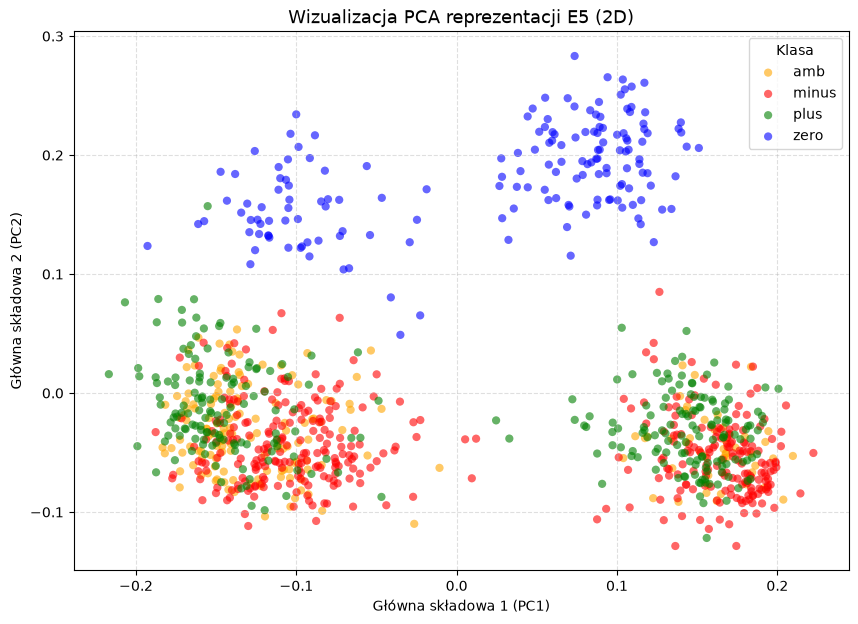

In [95]:
# Proszę zaimplementować PCA i przygotować wykres.

pca = PCA(n_components=2, random_state=RANDOM_STATE)
e5_emb_pca = pca.fit_transform(e5_emb)
points_with_target = []

plot_df = pd.DataFrame({
    "x": e5_emb_pca[:, 0],
    "y": e5_emb_pca[:, 1],
    "target": sample_df["target"].values
})

COLORS = {
    "plus": "green",
    "minus": "red",
    "zero": "blue",
    "amb": "orange"
}

plt.figure(figsize=(10, 7))

for target_name, group in plot_df.groupby("target"):
    plt.scatter(
        group["x"], 
        group["y"], 
        label=target_name,
        color=COLORS.get(target_name, "blue"),
        alpha=0.6,
        edgecolors="none",
        s=35
    )
    
plt.title("Wizualizacja PCA reprezentacji E5 (2D)", fontsize=13)
plt.xlabel("Główna składowa 1 (PC1)")
plt.ylabel("Główna składowa 2 (PC2)")
plt.legend(title="Klasa", loc="best")
plt.grid(True, linestyle="--", alpha=0.4)
plt.show()

In [96]:
var_pca1 = pca.explained_variance_ratio_[0]
var_pca2 = pca.explained_variance_ratio_[1]
total = var_pca1 + var_pca2
print(f"Wyjaśniona wariancja: PC1: {var_pca1:.2%}, PC2: {var_pca2:.2%}, suma: {total:.2%}")

Wyjaśniona wariancja: PC1: 12.44%, PC2: 5.47%, suma: 17.92%


In [97]:
display(plot_df.groupby("target")[["x", "y"]].agg(["mean", "std"]).round(3))

x             y       
         mean    std   mean    std
target                            
amb    -0.058  0.130 -0.035  0.035
minus   0.017  0.138 -0.048  0.035
plus    0.002  0.149 -0.022  0.038
zero    0.021  0.095  0.182  0.042

> PC1 i PC2 wyjaśniają łącznie 17.92% wariancji, `zero` tworzy osobne skupisko, bo to artykuły, a nie recenzje, `plus` i `minus` są częściowo rozdzielone wzdłuż PC1, ale jednak mocno się na siebie nakładają `amb` nie ma własnego obszaru i pokrywa się z `plus` oraz `minus`.

# Zadanie 8: Analiza przypadków

Proszę przygotować tabelę zawierającą dokładnie 12 przypadków, które pokazują ograniczenia reprezentacji wektorowych.

Pierwsze 6 przypadków należy znaleźć w wynikach najbliższych sąsiadów lub wyszukiwania. Powinny to być przykłady, w których podobieństwo jest wysokie, ale wynik jest problematyczny z punktu widzenia sentymentu lub intencji zapytania.

Kolejne 6 przypadków należy przygotować jako pary kontrastowe, np.:

```text
Hotel jest dobry.
Hotel nie jest dobry.
```

Dla każdej pary proszę policzyć podobieństwo w MiniLM i E5.

Tabela powinna zawierać:

| nr | typ | tekst A | tekst B / wynik | MiniLM | E5 | Δ MiniLM | Δ E5 | komentarz |
|---:|---|---|---|---:|---:|---:|---:|---|

Cosinusy E5 są skupione wysoko, więc nie wolno porównywać bezwzględnych wartości MiniLM i E5. Δ to różnica między cosinusem pary a cosinusem pary niezwiązanej tematycznie (np. "Hotel jest dobry." i "Samochód jest szybki.") liczonym tym samym modelem.

W komentarzu proszę używać krótkich kategorii, np.:

- negacja;
- wspólny temat;
- wspólne słownictwo;
- podobna forma;
- różny sentyment;
- bardzo krótki tekst;
- inna.


In [ ]:
# Proszę znaleźć 6 przypadków z danych, przygotować 6 par kontrastowych i zbudować tabelę 12 przypadków.

UNRELATED = "No i pojechalim… do domu. Mamy mundial cztery K: Kolumbia, Kazań, klęska. Czwarte K proszę sobie dopisać według własnego uznania."
EXAMPLES = [
    {
        "nr": 1,
        "type": "sąsiad",
        # 4657 
        "text_A": "obsługa w hotelu słaba , niezbyt uprzejma . w barze ciągły jej brak . jedzenie mało smaczne , nie urozmaicone . pokoje ok , czyste , duże . hotel ogólnie . . . - przerost formy nad treścią . . . nie polecam . hotel nie dba o gości . . .",
        # 5704 
        "text_B": "świetny hotel z bardzo uprzejmą obsługą , choć troszkę ospałą . śniadania bardzo dobre , choć obiady , które mieli śmy wykupione mogły by być do wyboru i nie zawsze mi smakowały . na basenie czysto , w grocie solnej bardzo przytulnie . odpoczęli śmy w stu procentach . pokoje zadbane . ceny na barze niskie . minusem jest to , że obsługa nie przynosi zamówień z baru do pokoju . . .",
        "comment": "wspólne słownictwo; różny sentyment (minus→plus)",
    },
    {
        "nr": 2,
        "type": "sąsiad",
        # 2264 
        "text_A": "była m u tej pani i niestety nie była to miła wizyta . bardzo nie rzyjemna pani położna , zrobiła mi łaskę , że mnie \" wcisła \" w kolejkę - a miała wizytę umówioną z 2 tygodniowym wyprzedzeniem > pani doktor też nie wykazywała zainteresowanie , była znudzona pacejentem ! ! ! ! nie polecam szczególnie dla dziewczyn , które przeżywają pierwszą wizytę u ginekologa !",
        # 83 
        "text_B": "pierwsza moja wizyta u pani doktor i jestem bardzo zadowolona . czekała m ponad godzinę w kolejce , ale wolę aby lekarz więcej czasu poświęcił pacjentowi , niż na odczepne przyjmował i mieścił się w czasie . poszła m z dość wstydliwym podejściem , a pani doktor bardzo dobrze mnie przyjęła , na spokojnie , starała się , aby m się nie stresowała , dużo doradzała , że mimo iż wcześniej bardzo stresowała m się wizytą u ginekologa , tutaj już nie będę miała obaw na kolejną wizytę .",
        "comment": "wspólny temat; różny sentyment (minus→plus)",
    },
    {
        "nr": 3,
        "type": "sąsiad",
        # 537
        "text_A": "była u dr we wtorek , dziś mamy sobotę i niestety nie widzę poprawy ; ( lekarz wydawał sie kompetentny i jakby wiedział co mowi ale niestety nie pomógł mi a rzekomo miało pomoc . ( mowa o wysypce na nogach i pozyskanej od lekarza robionego maści na lekkich sterydach )",
        # 1330
        "text_B": "była m u pana doktora już ładnych parę lat temu i muszę przyznać , że bardzo mi pomógł . miała m kłopoty z hemoroidami i ich świądem . przepisał mi receptę na maść robioną w aptece , tanią i rewelacyjną . do dziś używam kiedy tylko poczuję , że się coś dzieje . dzięki tej maści nie potrzebowała m na razie żadnej interwencji w temacie hemoroidów . maść załatwia sprawę . żadne , nawet drogie apteczne nie pomagały . dziękuję panie doktorze ! ! ! jedno muszę przyznać , że badanie rektoskopii było bardzo bolesne , choć nie mam porównania , bo było to moje na szczęście jedyne takie badanie .",
        "comment": "negacja; wspólny temat (minus→plus)",
    },
    {
        "nr": 4,
        "type": "wyszukiwanie",
        # 1
        "text_A": "Bardzo profesjonalny lekarz, wszystko dokładnie wytłumaczył i cierpliwie odpowiadał na pytania.",
        # 2414
        "text_B": "nie mam przekonania do tego lekarza . wizyta bardzo szybka , bez specjalnego wywiadu , ot zerknięcie na wyniki badań krwi i stwierdzenie , że są ok . z jego ust nie padło pytanie jak się czuję - a w sumie to najważniejszy objaw wymuszający choć zastanowienie się czy przeprowadzane leczenie jest prawidłowe i czy wymaga modyfikacji . lekarz miły i sympatyczny - to na pewno . wymagam stałej kontroli endokrynologa , ale nie zdecyduję się na ponowne wizyty .",
        "comment": "wspólny temat; różny sentyment (plus→minus)",
    },
    {
        "nr": 5,
        "type": "wyszukiwanie",
        # 2
        "text_A": "Paskudne jedzenie, codzienne dostawaliśmy te same, rozgotowane ziemniaki w mdłym i śmierdzoącym kotletem.",
        # 4720
        "text_B": "jedzenie pyszne , świeże , ogromne porcje , ceny bardzo dobre jak za taką jakość i ilość , obsługa zawsze na wysokim poziomie - uśmiechnięta i pomocna . regularnie wracamy i będziemy wracać . ostatnio pojawiło się kilka nowości w menu , to bardzo miłe urozmaicenie dla \" stałych \" bywalców . oby tak dalej . polecam gorąco !",
        "comment": "wspólny temat; różny sentyment (minus→plus)",
    },
    {
        "nr": 6,
        "type": "wyszukiwanie",
        # 4
        "text_A": "Typowy hotel wizyta, zero fajerwerków ale nie zawiódł nas.",
        # 4782
        "text_B": "oferta nie zgadza się z opisem w ofercie . brak plaży . . . najbliższa ok 7km od hotelu . jedzenie bez smaku . recepcja nas zlewała . tylko jeden z barmanów w porządku . nikomu nie polecam . . . ! ! ! ! ! 10 osób które były ze nami składa skargę na wezyra . . . bo z nim przylecieli śmy . . . pozdrawiam i odradzam ! ! ! ! ! ! ! !",
        "comment": "wspólny temat; inna – intencja zapytania (zero→minus)",
    },
    {
        "nr": 7,
        "type": "contrast",
        "text_A": "To był jeden z najlepszych hoteli w jakim byłem.",
        "text_B": "Nigdy nie byłem w gorszym hotelu.",
        "comment": "różny sentyment",
    },
    {
        "nr": 8,
        "type": "contrast",
        "text_A": "Oferowane śniadania były pyszne.",
        "text_B": "Oferowane śniadania były tragiczne.",
        "comment": "wspólne słownictwo, kontrast",
    },
    {
        "nr": 9,
        "type": "contrast",
        "text_A": "Mam same dobre wspomnienia po wizycie w tym ośrodku.",
        "text_B": "Tragicznie wspominam pobyt w tym ośrodku.",
        "comment": "różny sentyment",
    },
    {
        "nr": 10,
        "type": "contrast",
        "text_A": "Śniadania obfite, smaczne, ogólnie pięknie wszystko podane, wybór bardzo duży, urozmaicone, wszystko na na pięknej sali .",
        "text_B": "Tragicznie wspominam pobyt w tym ośrodku.",
        "comment": "rózna długość opini",
    },
    {
        "nr": 11,
        "type": "contrast",
        "text_A": "Pokój był czysty.",
        "text_B": "Pokój nie był czysty.",
        "comment": "negacja, bardzo krótki tekst",
    },
    {
        "nr": 12,
        "type": "contrast",
        "text_A": "Polecam ten obiekt każdemu.",
        "text_B": "Nie polecam tego obiektu nikomu.",
        "comment": "negacja",
    },
]

def pair_scores(model, a, b, prefix=""):
    a = normalize_text(f"{prefix}{a}")
    b = normalize_text(f"{prefix}{b}")
    unrelated = normalize_text(f"{prefix}{UNRELATED}")
    ea, eb, eu = model.encode([a, b, unrelated], normalize_embeddings=True, show_progress_bar=False)
    cos_ab = float(ea @ eb)
    base = float(ea @ eu)
    return cos_ab, cos_ab - base

res = []

for example in EXAMPLES:
    mini_lm_score, mini_lm_delta = pair_scores(miniLM, example["text_A"], example["text_B"])
    e5_score, e5_delta = pair_scores(e5, example["text_A"], example["text_B"], "query: ")
    res.append({
        "nr": example["nr"],
        "type": example["type"],
        "text_A": example["text_A"],
        "text_B": example["text_B"],
        "MiniLM": round(mini_lm_score, 2),
        "E5": round(e5_score, 2),
        "Δ MiniLM": round(mini_lm_delta, 2),
        "Δ E5": round(e5_delta, 2),
        "comment": example["comment"],
    })

res = pd.DataFrame(res)
res

,nr,type,text_A,text_B,MiniLM,E5,Δ MiniLM,Δ E5,comment
0,1,sąsiad,"obsługa w hotelu słaba , niezbyt uprzejma . w barze ciągły jej brak . jedzenie mało smaczne , nie urozmaicone . pokoje ok , czyste , duże . hotel ogólnie . . . - przerost formy...","świetny hotel z bardzo uprzejmą obsługą , choć troszkę ospałą . śniadania bardzo dobre , choć obiady , które mieli śmy wykupione mogły by być do wyboru i nie zawsze mi smakował...",0.75,0.93,0.61,0.08,wspólne słownictwo; różny sentyment (minus→plus)
1,2,sąsiad,"była m u tej pani i niestety nie była to miła wizyta . bardzo nie rzyjemna pani położna , zrobiła mi łaskę , że mnie "" wcisła "" w kolejkę - a miała wizytę umówioną z 2 tygodnio...","pierwsza moja wizyta u pani doktor i jestem bardzo zadowolona . czekała m ponad godzinę w kolejce , ale wolę aby lekarz więcej czasu poświęcił pacjentowi , niż na odczepne przy...",0.82,0.93,0.74,0.09,wspólny temat; różny sentyment (minus→plus)
2,3,sąsiad,"była u dr we wtorek , dziś mamy sobotę i niestety nie widzę poprawy ; ( lekarz wydawał sie kompetentny i jakby wiedział co mowi ale niestety nie pomógł mi a rzekomo miało pomoc...","była m u pana doktora już ładnych parę lat temu i muszę przyznać , że bardzo mi pomógł . miała m kłopoty z hemoroidami i ich świądem . przepisał mi receptę na maść robioną w ap...",0.68,0.92,0.61,0.09,negacja; wspólny temat (minus→plus)
3,4,wyszukiwanie,"Bardzo profesjonalny lekarz, wszystko dokładnie wytłumaczył i cierpliwie odpowiadał na pytania.","nie mam przekonania do tego lekarza . wizyta bardzo szybka , bez specjalnego wywiadu , ot zerknięcie na wyniki badań krwi i stwierdzenie , że są ok . z jego ust nie padło pytan...",0.54,0.90,0.47,0.08,wspólny temat; różny sentyment (plus→minus)
4,5,wyszukiwanie,"Paskudne jedzenie, codzienne dostawaliśmy te same, rozgotowane ziemniaki w mdłym i śmierdzoącym kotletem.","jedzenie pyszne , świeże , ogromne porcje , ceny bardzo dobre jak za taką jakość i ilość , obsługa zawsze na wysokim poziomie - uśmiechnięta i pomocna . regularnie wracamy i bę...",0.35,0.89,0.19,0.03,wspólny temat; różny sentyment (minus→plus)
5,6,wyszukiwanie,"Typowy hotel wizyta, zero fajerwerków ale nie zawiódł nas.",oferta nie zgadza się z opisem w ofercie . brak plaży . . . najbliższa ok 7km od hotelu . jedzenie bez smaku . recepcja nas zlewała . tylko jeden z barmanów w porządku . nikomu...,0.52,0.90,0.38,0.06,wspólny temat; inna – intencja zapytania (zero→minus)
6,7,contrast,To był jeden z najlepszych hoteli w jakim byłem.,Nigdy nie byłem w gorszym hotelu.,0.71,0.90,0.53,0.06,różny sentyment
7,8,contrast,Oferowane sniadania były pyszne.,Oferowane śniadania były tragiczne.,0.34,0.92,0.14,0.09,"wspólne słownictwo, kontrast"
8,9,contrast,Mam same dobre wspomniania po wizycie w tym ośrodku.,Tragicznie wspominam pobyt w tym ośrodku.,0.56,0.93,0.10,0.11,różny sentyment
9,10,contrast,"Śniadania obfite, smaczne, ogólnie pięknie wszystko podane, wybór bardzo duży, urozmaicone, wszystko na na pięknej sali .",Tragicznie wspominam pobyt w tym ośrodku.,0.02,0.84,-0.16,-0.01,rózna długość opini


> W parach z bezpośrednią negacją (np. nr 3 i nr 11) oba modele dają $\Delta > 0$, czyli zdanie i jego zaprzeczenie są bliżej siebie niż zdanie niezwiązane tematycznie. Najwyższe $\Delta$ ma para nr 2 (wśród par kontrastowych: para nr 7 w MiniLM oraz para nr 11 w E5): model koduje wspólny temat i leksykę, a nie przeciwny sentyment czy intencję. Najczęstsze kategorie błędów: wspólny temat, różny sentyment oraz negacja.

# Zadanie 9: Interpretacja wyników

To zadanie nie wymaga nowej implementacji.

Na podstawie wyników zadań 1-8 proszę odpowiedzieć:

1. W jakich sytuacjach TF-IDF zachowywał się lepiej od reprezentacji gęstych?
2. W jakich sytuacjach przewagę miały MiniLM lub E5?
3. Czy wysoka wartość `purity@k` oznacza, że reprezentacja jest ogólnie "lepsza semantycznie"?
4. Czy model o najlepszym `Precision@10` musi być najlepszym wyborem do klasyfikacji sentymentu?
5. Jakie dwa ograniczenia eksperymentu najbardziej wpływają na interpretację wyników?

Odpowiedzi powinny odwoływać się do uzyskanych liczb i przykładów.

> 1. Gdy o podobieństwie decyduje specyficzne słownictwo. Dla dokumentu `zero` (artykuł o programach lojalnościowych hoteli) TF-IDF znalazł 5/5 sąsiadów z tej samej klasy, a MiniLM 3/5. W wyszukiwaniu TF-IDF miał najwyższe Precision@5 = 0.55 i był najlepszy dla jednego zapytania `amb` (P@5 = 0.4, E5 i MiniLM 0.0). Jest też ok. 50–120× szybszy (0.56 ms/dok. vs 30.5 ms MiniLM i 67.0 ms E5).

> 2. Przy parafrazach bez wspólnych słów: „Hotel był bardzo dobry.” vs „Obiekt noclegowy zrobił na mnie świetne wrażenie.” TF-IDF daje 0.00, MiniLM 0.75, E5 0.93. E5 ma najlepszą jakość sąsiedztwa: purity@5 0.665 vs 0.579 (MiniLM) i 0.563 (TF-IDF). Jest też najlepszy w każdej klasie, np. plus 0.67 vs 0.49 (TF-IDF). W zadaniu 4 E5 trafił 16/20 sąsiadów z tą samą etykietą (TF-IDF 12/20, MiniLM 8/20).

> 3. Nie. Purity mierzy tylko zgodność etykiety sentymentu sąsiadów. Wysoka purity klasy `zero` wynika głównie z tego, że to inny gatunek tekstu, a nie z rozumienia znaczenia. Jednocześnie E5 uznaje zdania o przeciwnym sentymencie za bardzo bliskie: „Pokój był czysty.” / „Pokój nie był czysty.” ma `cos = 0.96`. Purity nie wychwytuje też negacji ani intencji zapytania.

> 4. Nie. Różnice Precision@10 są mniejsze niż 0.1, więc przy 8 zapytaniach nie wskazują zwycięzcy. Precision mierzy zwrócenie dokumentów tej samej klasy dla krótkiego zapytania, a klasyfikator uczy się na całych reprezentacjach z etykietami. Lepszym wskaźnikiem jest purity, a ostatecznie i tak trzeba wytrenować klasyfikator na zbiorze walidacyjnym.

> 5. Mała skala benchmarku: 8 zapytań i 1000 dokumentów. Pojedyncze zapytanie zmienia średnią o ponad 0.1, a etykieta sentymentu tylko przybliża relewantność. Nierówne okno modeli: MiniLM obcina 78.3% tekstów (128 tokenów), a E5 3.2% (512). Część przewagi E5 może wynikać z tego, że widzi całe recenzje, a nie z lepszej reprezentacji.

# Zadanie 10: Decyzja projektowa

To zadanie nie wymaga nowej implementacji.

Proszę wybrać reprezentację dla każdego z trzech zastosowań:

1. szybkie wyszukiwanie po dokładnych nazwach i terminach;
2. wyszukiwanie semantyczne parafraz;
3. przyszły system RAG.

Dla każdego zastosowania proszę podać:

- wybraną reprezentację;
- jeden wynik ilościowy (jakość lub koszt) uzasadniający decyzję;
- jeden obserwowany przypadek błędu lub ograniczenie;
- koszt, który należy zaakceptować.

Na końcu proszę odpowiedzieć jednym akapitem na pytanie:

**Dlaczego embeddingu nie należy utożsamiać ze "znaczeniem tekstu"?**

> 1. Szybkie wyszukiwanie po dokładnych nazwach i terminach → TF-IDF
> Wynik: 0.56 ms/dokument (vs 67.0 ms E5) i najwyższe Precision@5 = 0.55. Dla artykułu zero 5/5 sąsiadów, dopasowanych przez rzadkie terminy.
> Ograniczenie: parafraza „Obiekt noclegowy zrobił na mnie świetne wrażenie.” ma z „Hotel był bardzo dobry.” cosinus 0.00.
> Koszt: brak rozumienia synonimów i parafraz, duży wymiar (15 810, rzadki).
> 2. Wyszukiwanie semantyczne parafraz → MiniLM
> Wynik: najlepiej rozdziela parafrazę od przeciwnego sentymentu (A–B 0.75 vs A–C 0.38, różnica 0.37 wobec 0.02 w E5). Jest ponad 2× szybszy od E5 (30.5 vs 67.0 ms/dok.).
> Ograniczenie: okno 128 tokenów obcina 78.3% recenzji. W zadaniu 4 sąsiedzi łączyli się po temacie („operacja nosa”), a nie po ocenie.
> Koszt: nadaje się tylko do krótkich tekstów, a długie trzeba dzielić na fragmenty.
> 3. Przyszły system RAG → E5
> Wynik: najlepsza purity@5 = 0.665 i okno 512 tokenów (obcina tylko 3.2% tekstów).
> Ograniczenie: cosinusy są skupione wysoko (nawet niezwiązane pary ≈ 0.85–0.9), a negacja „Pokój był czysty.” / „Pokój nie był czysty.” daje 0.96. Progi podobieństwa trzeba kalibrować i należy pamiętać o prefiksach.
> Koszt: najwolniejszy (67.0 ms/dok).

> Embedding nie koduje znaczenia danej opini, tylko wspólny temat i słownictwo zapamiętane z treningu. Z tego powodu modele łączą teksty o tej samej tematyce, w dużej mierze ignorując negację.

# Karta modelu embeddingowego

Proszę wybrać jeden z dwóch modeli gęstej reprezentacji jako model rekomendowany do dalszych laboratoriów i utworzyć:

```text
artifacts/embedding_model_card.md
```

Karta powinna zawierać:

## Model
- nazwa checkpointu;
- wymiar reprezentacji;
- sposób normalizacji;
- wymagane prefiksy wejścia, jeśli dotyczy.

## Dane
- użyty zbiór;
- wielkość próbki;
- odsetek tekstów obciętych przez okno modelu;
- sposób doboru próbki.

## Koszt
- czas utworzenia reprezentacji;
- ms/dokument;
- rozmiar reprezentacji w pamięci.

## Jakość sąsiedztwa
- `purity@1`;
- `purity@5`;
- `purity@10`.

## Wyszukiwanie
- `Precision@5`;
- `Precision@10`.

## Analiza jakościowa
- najważniejsze obserwacje z PCA;
- dominujące typy błędów z analizy 20 przypadków.

## Zastosowanie
- do jakich zadań model jest rekomendowany;
- do jakich zadań nie należy go wybierać wyłącznie na podstawie tego laboratorium.

## Ograniczenia
- ograniczenia danych;
- ograniczenia benchmarku;
- ograniczenia samej reprezentacji.


# Wnioski

Na koniec pracy proszę zapisać krótkie wnioski. Każdy wniosek powinien wynikać z wykonanego eksperymentu i zawierać odwołanie do wyniku liczbowego, obserwacji albo konkretnego przypadku.

Nie należy przepisywać definicji TF-IDF, embeddingów ani podobieństwa cosinusowego.

> Skuteczność modeli: **E5** osiąga najwyższą ogólną czystość sąsiedztwa (purity@5 = 0.665), choć kosztuje to wielokrotnie dłuższy czas przetwarzania względem *TF-IDF*.

> Ograniczenia semantyczne: Reprezentacje gęste kodują głównie wspólny temat zamiast polaryzacji, przez co zdania z negacją lub przeciwne opinie uzyskują w **E5** podobieństwo powyżej 0.90.

> Trudne przypadki: Klasa opinii `amb` pozostaje problematyczna dla wszystkich podejść.
> 
> Okno modelu wpływa na wyniki: MiniLM obcina 78.3% recenzji, a E5 3.2%. Porównanie modeli nie jest więc w pełni uczciwe.
> 
> Benchmark wyszukiwania jest za mały, żeby wyłonić zwycięzcę: Precision@10 (0.48–0.52) różni się o mniej niż 0.1, mimo wyraźnych różnic w purity.

# Warunki zaliczenia laboratorium

Laboratorium jest ukończone, jeśli zawiera:

- [ ] własną implementację eksperymentu TF-IDF i podobieństwa cosinusowego;
- [ ] reprezentacje MiniLM i E5;
- [ ] deterministyczną próbkę danych;
- [ ] benchmark czasu i pamięci trzech reprezentacji;
- [ ] implementację wyszukiwania najbliższych sąsiadów;
- [ ] `purity@1`, `purity@5`, `purity@10`;
- [ ] osiem zapytań w benchmarku wyszukiwania;
- [ ] własną implementację `Precision@k`;
- [ ] `Precision@5` i `Precision@10`;
- [ ] wizualizację PCA;
- [ ] tabelę 12 przypadków błędów i par kontrastowych;
- [ ] sprawdzenie okna modeli (`max_seq_length`) i odsetka obciętych tekstów;
- [ ] purity z punktem odniesienia (losowi sąsiedzi) i per klasa;
- [ ] odpowiedzi do zadania interpretacyjnego (Zadanie 9);
- [ ] plik `artifacts/embedding_model_card.md`;
- [ ] od pięciu do ośmiu wniosków końcowych.